# TP Integrador — Métodos Predictivos para la Gestión
## Predicción del precio de autos según sus características

**Estructura del notebook:** i) Selección de datos y preprocesamiento · ii) Muestreo e inferencia · iii) Modelado estadístico clásico (regresión lineal) · iv) Machine Learning y validación · v) Conclusión comparativa.

**¿Cuál es la fuente de los datos?**

**Dataset:** [Precios de Autos según sus características](https://www.kaggle.com/datasets/CooperUnion/cardataset) (Kaggle,
CooperUnion). Datos reales de mercado scrapeados de Edmunds: ficha técnica y precio sugerido de ~12.000
modelos vendidos en EE.UU. entre 1990 y 2017. `Popularidad` proviene de menciones en Twitter por marca.

El dataset se carga en su formato original (`data.csv`, columnas en inglés) y lo primero que se hace es
traducir nombres de columnas y valores categóricos al español. **De ahí en adelante todo el notebook —
limpieza, outliers, guardado — trabaja exclusivamente con los nombres en español.** No queda ninguna
referencia a nombres viejos en inglés en ninguna celda.

**¿Qué representa cada fila (observación)?**

Cada fila es una versión/configuración específica de un modelo de auto, no un auto físico individual ni una venta. Es una combinación de marca + modelo + año.

**¿En qué período de tiempo se recolectaron?**

Cubre los años-modelo 1990 a 2017, y son datos históricos: hoy tienen casi una década de antigüedad como mínimo. Podria afectar al analisis Inflación y cambio de precios en 28 años o una crisis en la economia o en el sector automotor en ese tiempo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## 1. Carga del dataset original y traducción al español

> El dataset se lee directamente desde un link público de Google Drive, así que no hace falta subir ningún archivo.

In [2]:
# Usamos el ID que estaba en tu link
url = 'https://drive.google.com/uc?id=1HNe-mpytQubzXGQsM7mGlbUJai0fO7_t'

# Se lee directo de la web sin montar el Drive
df = pd.read_csv(url)
print("Dimensiones:", df.shape)
print("Columnas:", df.columns.tolist())

Dimensiones: (11914, 16)
Columnas: ['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP', 'Engine Cylinders', 'Transmission Type', 'Driven_Wheels', 'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style', 'highway MPG', 'city mpg', 'Popularity', 'MSRP']


In [3]:
mapa_columnas = {
    "Make": "Marca",
    "Model": "Modelo",
    "Year": "Anio",
    "Engine Fuel Type": "Tipo_Combustible",
    "Engine HP": "Potencia_HP",
    "Engine Cylinders": "Cilindros",
    "Transmission Type": "Tipo_Transmision",
    "Driven_Wheels": "Traccion",
    "Number of Doors": "Puertas",
    "Market Category": "Categoria_Mercado",
    "Vehicle Size": "Tamanio_Vehiculo",
    "Vehicle Style": "Estilo_Vehiculo",
    "highway MPG": "Rendimiento_Ruta_MPG",
    "city mpg": "Rendimiento_Ciudad_MPG",
    "Popularity": "Popularidad",
    "MSRP": "Precio",
}
df = df.rename(columns=mapa_columnas)


#combustibles mas limitados. menos opciones mas comodo
mapa_combustible = {
    "diesel": "diesel",
    "electric": "electrico",
    "flex-fuel (premium unleaded recommended/E85)": "flex-fuel",
    "flex-fuel (premium unleaded required/E85)": "flex-fuel",
    "flex-fuel (unleaded/E85)": "flex-fuel",
    "flex-fuel (unleaded/natural gas)": "flex-fuel",
    "natural gas": "gas natural",
    "premium unleaded (recommended)": "nafta premium",
    "premium unleaded (required)": "nafta premium",
    "regular unleaded": "nafta comun",
}

#aca en la q es manual automatizada, le podriamos poner directamente q es automatica
mapa_transmision = {
    "AUTOMATED_MANUAL": "MANUAL_AUTOMATIZADA",
    "AUTOMATIC": "AUTOMATICA",
    "DIRECT_DRIVE": "TRANSMISION_DIRECTA",
    "MANUAL": "MANUAL",
    "UNKNOWN": "DESCONOCIDA",
}
mapa_traccion = {
    "all wheel drive": "traccion integral (AWD)",
    "four wheel drive": "traccion 4x4",
    "front wheel drive": "traccion delantera",
    "rear wheel drive": "traccion trasera",
}
mapa_tamanio = {
    "Compact": "Compacto",
    "Midsize": "Mediano",
    "Large": "Grande",
}
mapa_estilo = {
    "2dr Hatchback": "Hatchback 2 puertas",
    "2dr SUV": "SUV 2 puertas",
    "4dr Hatchback": "Hatchback 4 puertas",
    "4dr SUV": "SUV 4 puertas",
    "Cargo Minivan": "Minivan de Carga",
    "Cargo Van": "Furgoneta de Carga",
    "Convertible": "Convertible",
    "Convertible SUV": "SUV Convertible",
    "Coupe": "Coupe",
    "Crew Cab Pickup": "Pickup Cabina Doble",
    "Extended Cab Pickup": "Pickup Cabina Extendida",
    "Passenger Minivan": "Minivan de Pasajeros",
    "Passenger Van": "Furgoneta de Pasajeros",
    "Regular Cab Pickup": "Pickup Cabina Simple",
    "Sedan": "Sedan",
    "Wagon": "Familiar (Wagon)",
}
mapa_categoria_mercado = {
    "Crossover": "Crossover",
    "Diesel": "Diesel",
    "Exotic": "Exotico",
    "Factory Tuner": "Preparado de Fabrica",
    "Flex Fuel": "Flex Fuel",
    "Hatchback": "Hatchback",
    "High-Performance": "Alto Rendimiento",
    "Hybrid": "Hibrido",
    "Luxury": "Lujo",
    "Performance": "Deportivo",
}

# .map() deja en NaN los valores ausentes automáticamente (no hace falta tratarlos todavía)
df["Tipo_Combustible"] = df["Tipo_Combustible"].map(mapa_combustible)
df["Tipo_Transmision"] = df["Tipo_Transmision"].map(mapa_transmision)
df["Traccion"] = df["Traccion"].map(mapa_traccion)
df["Tamanio_Vehiculo"] = df["Tamanio_Vehiculo"].map(mapa_tamanio)
df["Estilo_Vehiculo"] = df["Estilo_Vehiculo"].map(mapa_estilo)

def traducir_categoria_mercado(valor):
    if pd.isna(valor):
        return valor
    return ",".join(mapa_categoria_mercado[tag.strip()] for tag in valor.split(","))

df["Categoria_Mercado"] = df["Categoria_Mercado"].apply(traducir_categoria_mercado)

print(df.columns.tolist())
df.tail(10)

['Marca', 'Modelo', 'Anio', 'Tipo_Combustible', 'Potencia_HP', 'Cilindros', 'Tipo_Transmision', 'Traccion', 'Puertas', 'Categoria_Mercado', 'Tamanio_Vehiculo', 'Estilo_Vehiculo', 'Rendimiento_Ruta_MPG', 'Rendimiento_Ciudad_MPG', 'Popularidad', 'Precio']


,Marca,Modelo,Anio,Tipo_Combustible,Potencia_HP,Cilindros,Tipo_Transmision,Traccion,Puertas,Categoria_Mercado,Tamanio_Vehiculo,Estilo_Vehiculo,Rendimiento_Ruta_MPG,Rendimiento_Ciudad_MPG,Popularidad,Precio
11904,BMW,Z8,2002,nafta premium,394.0,8.0,MANUAL,traccion trasera,2.0,"Exotico,Lujo,Alto Rendimiento",Compacto,Convertible,19,12,3916,130000
11905,BMW,Z8,2003,nafta premium,394.0,8.0,MANUAL,traccion trasera,2.0,"Exotico,Lujo,Alto Rendimiento",Compacto,Convertible,19,12,3916,131500
11906,Acura,ZDX,2011,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,"Crossover,Hatchback,Lujo",Mediano,Hatchback 4 puertas,23,16,204,46020
11907,Acura,ZDX,2011,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,"Crossover,Hatchback,Lujo",Mediano,Hatchback 4 puertas,23,16,204,56570
11908,Acura,ZDX,2011,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,"Crossover,Hatchback,Lujo",Mediano,Hatchback 4 puertas,23,16,204,50520
11909,Acura,ZDX,2012,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,"Crossover,Hatchback,Lujo",Mediano,Hatchback 4 puertas,23,16,204,46120
11910,Acura,ZDX,2012,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,"Crossover,Hatchback,Lujo",Mediano,Hatchback 4 puertas,23,16,204,56670
11911,Acura,ZDX,2012,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,"Crossover,Hatchback,Lujo",Mediano,Hatchback 4 puertas,23,16,204,50620
11912,Acura,ZDX,2013,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,"Crossover,Hatchback,Lujo",Mediano,Hatchback 4 puertas,23,16,204,50920
11913,Lincoln,Zephyr,2006,nafta comun,221.0,6.0,AUTOMATICA,traccion delantera,4.0,Lujo,Mediano,Sedan,26,17,61,28995


**Análisis:** el dataset ya queda con sus 16 columnas renombradas y los valores categóricos
traducidos (`Marca` y `Modelo` se mantienen igual por ser nombres propios). Los valores que eran `NaN`
en el dataset original siguen siendo `NaN` después de traducir — el mapeo no inventa datos, solo
renombra lo que ya existía. Recién ahora arranca la limpieza, trabajando siempre con estos nombres.

# Diccionario de Variables del Dataset

### 1. Variables de Identificación y Categoría

*   **`Marca`**
    *   **Qué representa:** La empresa fabricante del vehículo (por ejemplo: BMW, Ford, Toyota, Tesla, Chevrolet, Audi, etc.).
    *   **Tipo:** Cualitativa nominal.
*   **`Modelo`**
    *   **Qué representa:** El nombre comercial específico del auto dentro de la marca (por ejemplo: 1 Series, Mustang, Corolla, Model S).
    *   **Tipo:** Cualitativa nominal de alta cardinalidad.

---

### 2. Variables de Configuración y Mecánica

*   **`Anio`**
    *   **Qué representa:** El año de fabricación o el año-modelo comercial del vehículo (abarca desde 1990 hasta 2017).
    *   **Tipo:** Cuantitativa discreta.
    
*   **`Tipo_Combustible`**
    *   **Qué representa:** El tipo de energía o combustible que requiere el motor para funcionar.
    *   **Valores clave:**
        *   *nafta comun (regular unleaded):* Nafta de octanaje estándar.
        *   *nafta premium (premium unleaded):* Nafta de mayor octanaje para motores de alta exigencia.
        *   *diesel:* Combustible gasoil para motores diésel.
        *   *electrico:* Vehículos 100% eléctricos (sin combustión).
        *   *flex-fuel:* Vehículos preparados para usar mezclas de nafta y etanol (E85).
        *   *gas natural:* Motores adaptados para GNC/GNV.
    *   **Tipo:** Cualitativa nominal.
*   **`Potencia_HP`**
    *   **Qué representa:** La potencia máxima del motor medida en caballos de fuerza (*Horsepower*). A mayor valor, mayor es la fuerza y velocidad potencial del auto.
    *   **Tipo:** Cuantitativa continua.
*   **`Cilindros`**
    *   **Qué representa:** La cantidad de cilindros que posee el bloque del motor térmico (varía habitualmente de 3 a 16). En el caso de los autos eléctricos, se imputó correctamente con 0 ya que carecen de cilindros.
    *   **Tipo:** Cuantitativa discreta.
*   **`Tipo_Transmision`**
    *   **Qué representa:** El mecanismo utilizado para cambiar las marchas del vehículo.
    *   **Valores clave:**
        *   *MANUAL:* Caja de cambios tradicional operada por el conductor con pedal de embrague.
        *   *AUTOMATICA:* Transmisión que realiza los cambios de marcha de forma autónoma.
        *   *MANUAL_AUTOMATIZADA (Automated Manual):* Caja manual donde un sistema electrónico e hidráulico gestiona el embrague y los cambios.
        *   *TRANSMISION_DIRECTA (Direct Drive):* Común en vehículos eléctricos que no requieren de una caja de cambios de múltiples marchas.
    *   **Tipo:** Cualitativa nominal.
*   **`Traccion`**
    *   **Qué representa:** Determina a qué ruedas se envía la fuerza del motor para propulsar el vehículo. Es clave para el comportamiento dinámico y el agarre.
    *   **Valores clave:**
        *   *traccion delantera (Front-wheel drive - FWD):* La fuerza se envía exclusivamente a las ruedas del frente. Es el estándar de los autos comunes por ser eficiente y económico.
        *   *traccion trasera (Rear-wheel drive - RWD):* La fuerza va a las ruedas de atrás. Muy común en autos deportivos y de alta gama por su mejor distribución de pesos y dinámica de manejo.
        *   *traccion integral (AWD) (All-wheel drive):* Tracción permanente en las 4 ruedas ideal para pavimento mojado, curvas exigentes y asfalto.
        *   *traccion 4x4 (Four-wheel drive - 4WD):* Tracción en las 4 ruedas pensada para terrenos difíciles (*off-road*), que suele contar con modos de transferencia manual (alta/baja).
    *   **Tipo:** Cualitativa nominal.
*   **`Puertas`**
    *   **Qué representa:** La cantidad física de puertas de acceso del auto (típicamente 2, 3 o 4).
    *   **Tipo:** Cuantitativa discreta.

---

### 3. Variables de Aspecto Físico y Carrocería

*   **`Tamanio_Vehiculo`**
    *   **Qué representa:** La categoría de tamaño según las dimensiones del chasis.
    *   **Valores clave:** Compacto (*Compact*), Mediano (*Midsize*), Grande (*Large*).
    *   **Tipo:** Cualitativa ordinal.
*   **`Estilo_Vehiculo`**
    *   **Qué representa:** El formato físico, tipo de carrocería y propósito de diseño del vehículo.
    *   **Valores clave:**
        *   *Sedan:* Auto clásico de 3 volúmenes independientes (motor, habitáculo y baúl cerrado).
        *   *Coupe:* Auto de estilo deportivo, generalmente de 2 puertas y techo inclinado.
        *   *Convertible:* Auto con techo plegable o descapotable.
        *   *Hatchback (2 y 4 puertas):* Auto compacto donde el baúl está integrado al habitáculo y tiene un portón trasero que abre con el vidrio.
        *   *SUV (2 y 4 puertas) (Sport Utility Vehicle):* Vehículo utilitario deportivo, con mayor despeje del suelo y aspecto aventurero.
        *   *Familiar (Wagon):* Similar a un sedán pero con el techo extendido hasta atrás para priorizar el espacio de carga familiar.
        *   *Pickup (Cabina Simple, Doble y Extendida):* Vehículo de carga con caja abierta en la parte trasera.
        *   *Minivan / Furgoneta (de Carga o Pasajeros):* Vehículos monovolumen de gran volumen interno diseñados para transporte comercial o de muchos pasajeros.
    *   **Tipo:** Cualitativa nominal.

---

### 4. Variables de Consumo y Comercialización

*   **`Rendimiento_Ciudad_MPG`**
    *   **Qué representa:** La eficiencia de combustible en ciclo urbano, medida en millas por galón (MPG). A mayor MPG, más eficiente es el auto (gasta menos combustible). En la ciudad suele ser menor que en ruta debido a las frenadas y arranques.
    *   **Tipo:** Cuantitativa continua.
*   **`Rendimiento_Ruta_MPG`**
    *   **Qué representa:** La eficiencia de combustible en autopista o ruta, medida en millas por galón (MPG). Suele ser un rendimiento más alto (más eficiente) que el de ciudad al mantener una velocidad constante.
    *   **Tipo:** Cuantitativa continua.
*   **`Precio` (Variable Target)**
    *   **Qué representa:** El precio sugerido de venta al público en dólares estadounidenses (MSRP - *Manufacturer's Suggested Retail Price*).
    *   **Tipo:** Cuantitativa continua.

In [4]:
#mostrar los diferentes tipos de valores para Estilo_vehiculo y sus canatidades
df["Estilo_Vehiculo"].value_counts()

,count
Estilo_Vehiculo,
Sedan,3048
SUV 4 puertas,2488
Coupe,1211
Convertible,793
Hatchback 4 puertas,702
Pickup Cabina Doble,681
Pickup Cabina Extendida,623
Familiar (Wagon),592
Hatchback 2 puertas,506


In [5]:
df["Categoria_Mercado"].value_counts()

,count
Categoria_Mercado,
Crossover,1110
Flex Fuel,872
Lujo,855
"Lujo,Deportivo",673
Hatchback,641
...,...
"Crossover,Exotico,Lujo,Alto Rendimiento",1
"Crossover,Exotico,Lujo,Deportivo",1
"Deportivo,Hibrido",1


## 2. Valores faltantes

In [6]:
nulos = df.isnull().sum()
pct = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({"nulos": nulos, "%": pct})
resumen_nulos = resumen_nulos[resumen_nulos["nulos"] > 0].sort_values("%", ascending=False)
resumen_nulos

,nulos,%
Categoria_Mercado,3742,31.41
Potencia_HP,69,0.58
Cilindros,30,0.25
Puertas,6,0.05
Tipo_Combustible,3,0.03


**Análisis:** cinco columnas tienen valores faltantes:

- **`Categoria_Mercado`** (31.41%, 3.742 filas): proporción demasiado alta como para eliminar esas filas
  o imputar con una categoría estimada sin fundamento, al ser un campo multi-etiqueta de texto libre. Se
  trata como información genuina ausente: "este auto no tiene una categoría de mercado destacada".
- **`Potencia_HP`** (0.58%, 69 filas) y **`Cilindros`** (0.25%, 30 filas): numéricas, con muy baja
  proporción de nulos — se imputan para no perder información de otras columnas.
- **`Puertas`** (0.05%, 6 filas) y **`Tipo_Combustible`** (0.03%, 3 filas): proporción insignificante.

In [7]:
#eliminar la columna de Categoria_Mercado ya que tiene el 30% de valores faltantes, y al ser valores multietiqueta se va a complicar tratarlos
df.drop(columns=["Categoria_Mercado"], inplace=True)


In [8]:
print("Cilindros nulos según tipo de combustible:")
print(df[df["Cilindros"].isnull()]["Tipo_Combustible"].value_counts())

Cilindros nulos según tipo de combustible:
Tipo_Combustible
nafta premium    17
electrico        10
nafta comun       3
Name: count, dtype: int64


**Análisis:** de los 30 nulos en `Cilindros`, 10 corresponden a autos **eléctricos**. No es un dato
faltante en sentido estadístico: un motor eléctrico no tiene cilindros, por lo que corresponde una
**corrección lógica** (imputar 0) y no una imputación estadística. Los 20 restantes (combustión a nafta)
sí son faltantes genuinos y se imputan con la mediana del grupo (`Estilo_Vehiculo`).

In [9]:
# Corrección lógica: motores eléctricos no tienen cilindros
mask_electrico = df["Tipo_Combustible"] == "electrico"
df.loc[mask_electrico & df["Cilindros"].isnull(), "Cilindros"] = 0

# Resto de los nulos (motores a combustión): imputación por mediana según estilo de vehículo
df["Cilindros"] = df.groupby("Estilo_Vehiculo")["Cilindros"].transform(
    lambda s: s.fillna(s.median())
)

print("Nulos restantes en Cilindros:", df["Cilindros"].isnull().sum())

Nulos restantes en Cilindros: 0


In [10]:
print("Potencia_HP nulos según marca:")
print(df[df["Potencia_HP"].isnull()]["Marca"].value_counts().head(10))

Potencia_HP nulos según marca:
Marca
Tesla         18
Ford          13
Nissan        10
Lincoln        8
Chevrolet      6
Kia            5
FIAT           3
Toyota         2
Honda          2
Mitsubishi     1
Name: count, dtype: int64


**Análisis:** los nulos de `Potencia_HP` se concentran en Tesla (18 de 69), seguido de Ford, Nissan y
Lincoln. No hay un patrón que sugiera un sesgo sistemático de un único segmento, por lo que se imputa con
la **mediana agrupada por `Estilo_Vehiculo` y `Cilindros`** (vehículos del mismo tipo y tamaño de motor
tienen potencias similares), en vez de usar la mediana global, que subestimaría la potencia real de autos
de alta gama y la sobreestimaría en los compactos.

In [11]:
df["Potencia_HP"] = df.groupby(["Estilo_Vehiculo", "Cilindros"])["Potencia_HP"].transform(
    lambda s: s.fillna(s.median())
)
# Fallback por si alguna combinación de grupo quedó sin mediana calculable
df["Potencia_HP"] = df["Potencia_HP"].fillna(df["Potencia_HP"].median())

print("Nulos restantes en Potencia_HP:", df["Potencia_HP"].isnull().sum())

Nulos restantes en Potencia_HP: 0


In [12]:
print(df[df["Puertas"].isnull()][["Marca", "Modelo", "Estilo_Vehiculo"]])

        Marca   Modelo Estilo_Vehiculo
4666  Ferrari       FF           Coupe
6930    Tesla  Model S           Sedan
6931    Tesla  Model S           Sedan
6932    Tesla  Model S           Sedan
6933    Tesla  Model S           Sedan
6934    Tesla  Model S           Sedan


**Análisis:** los 6 nulos de `Puertas` corresponden a un Ferrari FF (Coupe) y cinco Tesla Model S
(Sedan). Se imputan con la moda de `Estilo_Vehiculo` (Coupe → 2 puertas, Sedan → 4 puertas), una
corrección lógica directa a partir de una columna relacionada.

In [13]:
df["Puertas"] = df.groupby("Estilo_Vehiculo")["Puertas"].transform(
    lambda s: s.fillna(s.mode().iloc[0]) if not s.mode().empty else s
)

df["Tipo_Combustible"] = df["Tipo_Combustible"].fillna(df["Tipo_Combustible"].mode().iloc[0])

#df["Categoria_Mercado"] = df["Categoria_Mercado"].fillna("No Especificado")

print("Nulos totales restantes en el dataset:", df.isnull().sum().sum())

Nulos totales restantes en el dataset: 0


**Análisis:** después del tratamiento, el dataset queda sin valores faltantes y **sin eliminar ninguna fila**. En resumen:

- `Categoria_Mercado` (31 % de vacíos, multietiqueta): se **eliminó la columna**.
- `Cilindros`: corrección lógica (0 en los eléctricos) e imputación por **mediana según estilo** en el resto.
- `Potencia_HP`: imputación por **mediana según estilo y cilindros**.
- `Puertas`: corrección lógica con la **moda según estilo** (Coupe → 2, Sedan → 4).
- `Tipo_Combustible` (3 filas): imputación con la **moda** general.

In [14]:
df.columns

Index(['Marca', 'Modelo', 'Anio', 'Tipo_Combustible', 'Potencia_HP', 'Cilindros', 'Tipo_Transmision', 'Traccion',
       'Puertas', 'Tamanio_Vehiculo', 'Estilo_Vehiculo', 'Rendimiento_Ruta_MPG', 'Rendimiento_Ciudad_MPG',
       'Popularidad', 'Precio'],
      dtype='object')

**¿Cuántas variables (columnas) tienen y de qué tipo son?**

| Variable | Qué representa | Tipo | Estado |
|---|---|---|---|
| `Marca` | Fabricante (BMW, Toyota, etc.), 48 valores distintos | Cualitativa nominal | Se usa agrupada en gamas |
| `Modelo` | Modelo específico, más de 900 valores distintos | Cualitativa nominal (altísima cardinalidad) | No se usa como predictor |
| `Anio` | Año del modelo (1990–2017) | Cuantitativa discreta | Se usa |
| `Tipo_Combustible` | Nafta común, premium, diésel, eléctrico, flex-fuel, gas natural | Cualitativa nominal | Se usa |
| `Potencia_HP` | Potencia del motor en caballos de fuerza | Cuantitativa continua | Se usa |
| `Cilindros` | Cantidad de cilindros (0 a 16) | Cuantitativa discreta | Se usa |
| `Tipo_Transmision` | Automática, manual, manual automatizada, directa | Cualitativa nominal | Se usa |
| `Traccion` | Delantera, trasera, integral (AWD), 4x4 | Cualitativa nominal | Se usa |
| `Puertas` | Cantidad de puertas (2, 3, 4) | Cuantitativa discreta | Se usa |
| `Categoria_Mercado` | Etiquetas de segmento combinadas (ej. "Lujo,Deportivo") | Cualitativa nominal multietiqueta | **Eliminada** (31 % de vacíos) |
| `Tamanio_Vehiculo` | Compacto, Mediano, Grande | Cualitativa ordinal | Se usa |
| `Estilo_Vehiculo` | Sedan, SUV, Coupe, Pickup, Convertible, etc. (16 categorías) | Cualitativa nominal | Se usa para estratificar la muestra |
| `Rendimiento_Ruta_MPG` | Rendimiento en ruta (millas por galón) | Cuantitativa continua | Se combina en un promedio |
| `Rendimiento_Ciudad_MPG` | Rendimiento en ciudad (millas por galón) | Cuantitativa continua | Se combina en un promedio |
| `Popularidad` | Puntaje de menciones en Twitter, asignado por marca | Cuantitativa discreta | **Eliminada** (redundante con la marca) |
| `Precio` | Precio sugerido de venta en USD (**target**) | Cuantitativa continua | Variable objetivo |

En total son **16 variables**: 8 cualitativas (7 nominales y 1 ordinal) y 8 cuantitativas (4 discretas y 4 continuas).

**¿Cuál es la variable "Target" (objetivo)?**

La variable target es `Precio` (numérica continua) → problema de **Regresión**.

### Preguntas obligatorias 3 y 4

**3. Ruido y variables no informativas**
* **Variables de identificación:** no hay un ID único por fila. `Modelo` funciona casi como un identificador (más de 900 valores distintos), por lo que no se usa como predictor.
* **Varianza cero:** ninguna columna es constante.
* **Variables redundantes:** `Popularidad` es un atributo de la marca, no del auto (un único valor por marca), y se eliminó. `Rendimiento_Ciudad_MPG` y `Rendimiento_Ruta_MPG` dicen casi lo mismo (r = 0,89) y se combinaron en un promedio.
* **Faltantes:** `Categoria_Mercado` tenía un 31 % de valores vacíos y se descartó. El resto de las columnas tenía menos del 1 % y se imputó.

**4. Definición del problema**
* **Pregunta:** ¿podemos estimar el precio sugerido de un auto a partir de su ficha técnica (potencia, año, motor, transmisión, tamaño y gama de la marca)?
* **Necesidad que resuelve:** una concesionaria, una aseguradora o un sitio de compraventa necesita tasar autos de forma rápida y consistente. El modelo serviría para sugerir un precio de referencia o detectar publicaciones con precios fuera de mercado.
* **Hipótesis inicial:** esperamos que las variables más importantes sean la **potencia** del motor, la **marca** (prestigio) y el **año** del modelo, y que un mejor rendimiento de combustible se asocie con autos más baratos.

## 3. Registros duplicados

In [15]:
n_duplicados = df.duplicated().sum()
print("Filas duplicadas exactas:", n_duplicados)
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

Filas duplicadas exactas: 720


,Marca,Modelo,Anio,Tipo_Combustible,Potencia_HP,Cilindros,Tipo_Transmision,Traccion,Puertas,Tamanio_Vehiculo,Estilo_Vehiculo,Rendimiento_Ruta_MPG,Rendimiento_Ciudad_MPG,Popularidad,Precio
8536,Acura,RL,2010,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,Mediano,Sedan,22,16,204,50450
8537,Acura,RL,2010,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,Mediano,Sedan,22,16,204,50450
8539,Acura,RL,2011,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,Mediano,Sedan,24,17,204,51350
8540,Acura,RL,2011,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,Mediano,Sedan,24,17,204,51350
8544,Acura,RL,2012,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,Mediano,Sedan,24,17,204,52350
8546,Acura,RL,2012,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,Mediano,Sedan,24,17,204,52350


**Análisis:** se detectan filas 100% idénticas en las 16 columnas — mismo auto, mismo año, mismas
specs y mismo precio repetido más de una vez. No representan autos distintos sino el mismo registro
cargado más de una vez en el scraping original, así que se eliminan sin pérdida de información real.

In [16]:
shape_antes = df.shape
df = df.drop_duplicates().reset_index(drop=True)
print(f"Filas: {shape_antes[0]} -> {df.shape[0]} (se eliminaron {shape_antes[0] - df.shape[0]} duplicados)")

Filas: 11914 -> 11194 (se eliminaron 720 duplicados)


## 4. Eliminación de `Popularidad`

In [17]:
print("Marcas:", df["Marca"].nunique(), "| Valores distintos de Popularidad:", df["Popularidad"].nunique())
print("Máximo de valores distintos de Popularidad dentro de una misma marca:",
      df.groupby("Marca")["Popularidad"].nunique().max())
print("Correlación Popularidad vs Precio:", round(df["Popularidad"].corr(df["Precio"]), 3))

df.groupby("Marca")["Popularidad"].first().sort_values(ascending=False).head(5)

Marcas: 48 | Valores distintos de Popularidad: 48
Máximo de valores distintos de Popularidad dentro de una misma marca: 1
Correlación Popularidad vs Precio: -0.048


,Popularidad
Marca,
Ford,5657
BMW,3916
Audi,3105
Ferrari,2774
Honda,2202


**Análisis y decisión:** `Popularidad` toma **exactamente un valor por marca** (48 marcas, 48 valores
distintos): no describe al auto, describe a la marca. Se elimina por estos motivos:

1. **Es redundante con `Marca`.** Al ser constante dentro de cada marca, no aporta nada que `Marca` no tenga
   ya; es solo una etiqueta numérica de la marca.
2. **No varía entre autos de la misma marca.** Una versión básica y una de lujo del mismo modelo, o un auto
   de 1995 y uno de 2017, tienen el mismo puntaje, así que no ayuda a explicar las diferencias de `Precio`
   dentro de una marca.
3. **Es anacrónica.** Son menciones en Twitter (la red existe desde 2006) medidas en un único momento, pero
   se le asignan a autos desde 1990.
4. **No se relaciona con el target.** La correlación con `Precio` es de −0,048, prácticamente nula, y la marca
   con mayor puntaje (Ford) no es de las más caras.
5. **Induciría a error al modelar.** Como variable numérica, un modelo le asignaría un efecto lineal a lo que
   en realidad es un identificador de marca.

La información de marca ya queda representada por `Marca`.

In [18]:
df = df.drop(columns=["Popularidad"])

print("Dimensiones:", df.shape)
print("Duplicados exactos tras eliminar Popularidad:", df.duplicated().sum())
print("Columnas:", df.columns.tolist())

Dimensiones: (11194, 14)
Duplicados exactos tras eliminar Popularidad: 0
Columnas: ['Marca', 'Modelo', 'Anio', 'Tipo_Combustible', 'Potencia_HP', 'Cilindros', 'Tipo_Transmision', 'Traccion', 'Puertas', 'Tamanio_Vehiculo', 'Estilo_Vehiculo', 'Rendimiento_Ruta_MPG', 'Rendimiento_Ciudad_MPG', 'Precio']


## 5. Inconsistencias lógicas

In [19]:
n_2000 = (df["Precio"] == 2000).sum()
print(f"Filas con Precio exactamente igual a 2000: {n_2000}")
df[df["Precio"] == 2000][["Marca", "Modelo", "Anio", "Potencia_HP", "Precio"]].head(10)

Filas con Precio exactamente igual a 2000: 747


,Marca,Modelo,Anio,Potencia_HP,Precio
16,Audi,100,1992,172.0,2000
17,Audi,100,1992,172.0,2000
18,Audi,100,1992,172.0,2000
19,Audi,100,1993,172.0,2000
20,Audi,100,1993,172.0,2000
21,Audi,100,1993,172.0,2000
22,Audi,100,1994,172.0,2000
23,Audi,100,1994,172.0,2000
24,Audi,100,1994,172.0,2000
25,Audi,100,1994,172.0,2000


**Análisis — hallazgo clave de inconsistencia lógica:** 747 filas (distintas marcas, modelos y años, desde un Audi 100 de 1992 hasta una Suzuki X-90 de 1998) tienen el valor **exacto** `Precio = 2000`. En el dataset original eran 1.036; las otras 289 eran copias exactas que ya se eliminaron al quitar duplicados.

Es prácticamente imposible que autos tan distintos tengan el mismo precio exacto al dólar. Todo indica que `2000` es un **valor de relleno** que se cargó cuando no se encontró el precio real, no un precio de mercado. Mantenerlo distorsionaría cualquier modelo de regresión sobre `Precio`. Como es la variable **target**, tampoco corresponde imputarla: sería inventar la respuesta que el modelo tiene que predecir. Por eso se eliminan esas filas.

In [20]:
shape_antes = df.shape
df = df[df["Precio"] != 2000].reset_index(drop=True)
print(f"Filas: {shape_antes[0]} -> {df.shape[0]} (se eliminaron {shape_antes[0] - df.shape[0]} filas con Precio placeholder)")

Filas: 11194 -> 10447 (se eliminaron 747 filas con Precio placeholder)


In [21]:
print("Rango de años:", df["Anio"].min(), "-", df["Anio"].max())
print("Marcas únicas:", df["Marca"].nunique())

Rango de años: 1990 - 2017
Marcas únicas: 48


**Análisis:** no se detectan inconsistencias adicionales — el rango de `Anio` (1990-2017) es
coherente con la descripción del dataset y no hay duplicados de marca por errores de tipeo, por lo que no
hace falta normalizar texto en `Marca`.

## 6. Outliers

Se analizan las variables numéricas más relevantes para el problema de regresión: `Precio` (target),
`Potencia_HP`, `Cilindros`, `Rendimiento_Ciudad_MPG` y `Rendimiento_Ruta_MPG`. El análisis se hace
**después** de limpiar duplicados e inconsistencias lógicas, para que la fila placeholder de
`Precio = 2000` (ya eliminada) no distorsione los boxplots y el Z-score con un pico artificial en el
extremo inferior.

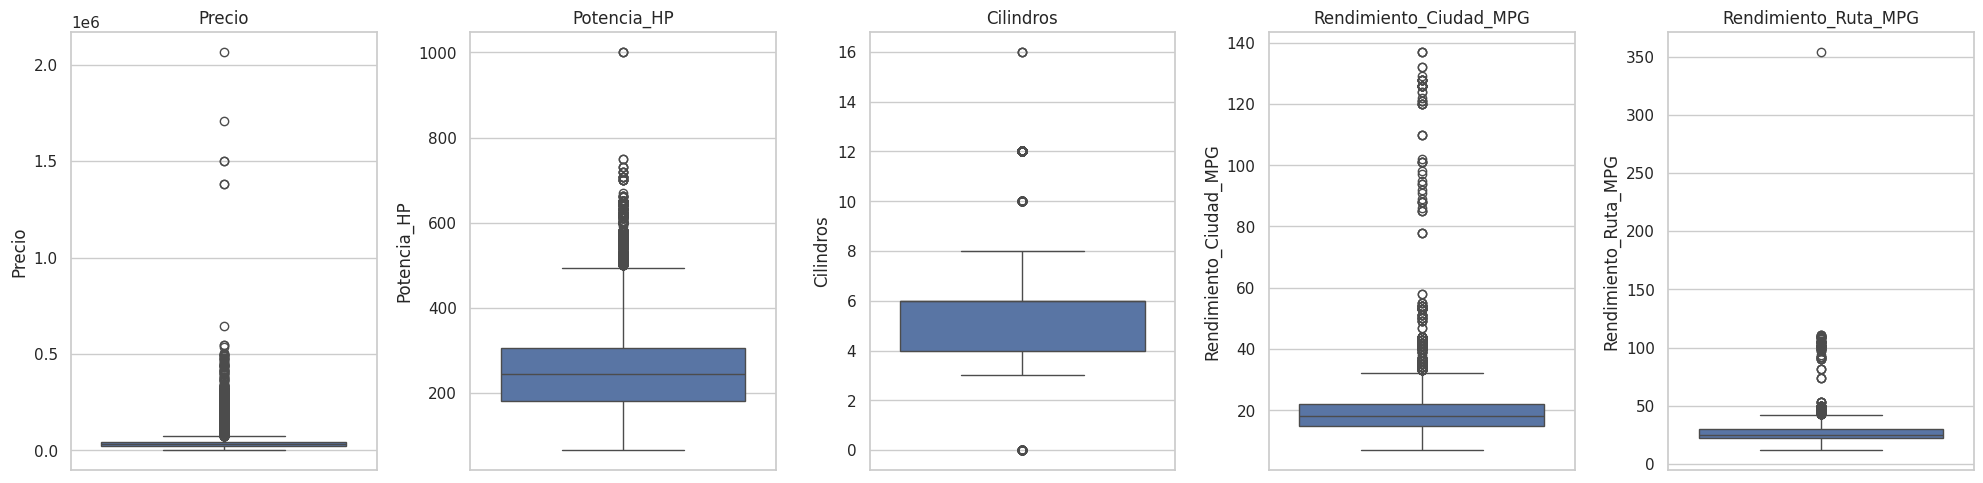

In [22]:
columnas_numericas = ["Precio", "Potencia_HP", "Cilindros", "Rendimiento_Ciudad_MPG", "Rendimiento_Ruta_MPG"]

fig, axes = plt.subplots(1, len(columnas_numericas), figsize=(20, 5))
for ax, col in zip(axes, columnas_numericas):
    sns.boxplot(y=df[col], ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.tight_layout()
plt.savefig("boxplots_outliers.png", dpi=110)
plt.show()

**Análisis:** `Precio` y `Potencia_HP` muestran una cola larga hacia arriba, con numerosos puntos
por encima del bigote superior — son los autos de alta gama/deportivos (Bugatti, Lamborghini, Ferrari,
Maybach). `Rendimiento_Ciudad_MPG` y `Rendimiento_Ruta_MPG` también muestran outliers superiores,
asociados a híbridos/eléctricos de muy bajo consumo. `Cilindros` tiene menos dispersión por ser discreta
con pocos valores posibles (0 a 16).

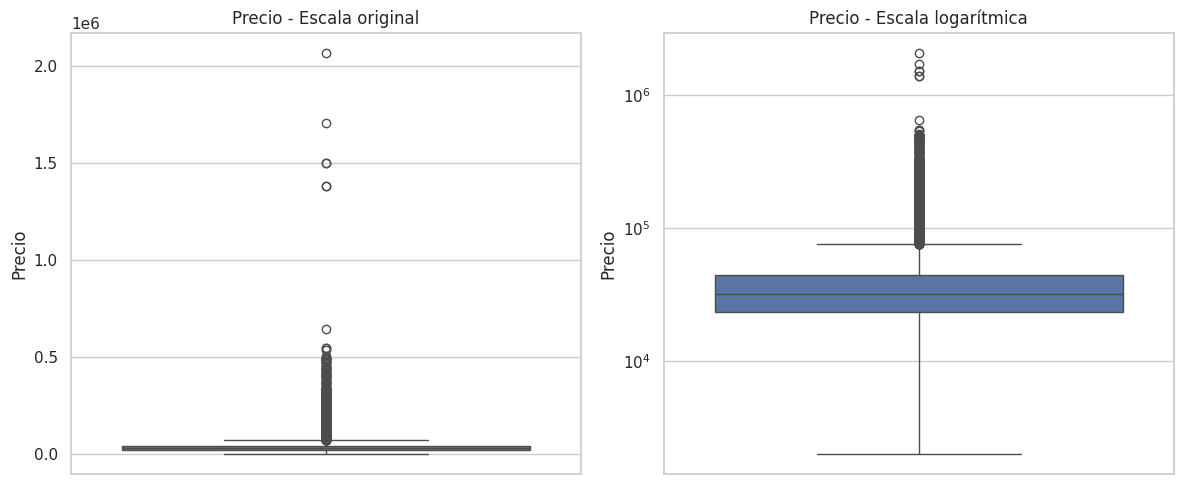

In [23]:
#aca probando con precio por separada para mostrarlo en escala logaritmica
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Precio"], ax=axes[0])
axes[0].set_title("Precio - Escala original")

sns.boxplot(y=df["Precio"], ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Precio - Escala logarítmica")

plt.tight_layout()
plt.show()

en el grafico de la izquierda, Se observan varios puntos aislados que se extienden hacia arriba, llegando incluso a superar los 2 millones (2.0 × 10⁶). Esto demuestra que los datos tienen una alta asimetría hacia la derecha (unos pocos valores son extremadamente altos en comparación con el resto).

en el de la derecha,aplciamos logaritmo al precio:  **Esto "estira" los valores más bajos y "comprime" los más altos**.  

Permite ver con mayor precisión la densidad y dispersión de la gran cantidad de valores atípicos (la línea negra vertical de puntos) que antes aparecían amontonados.


In [24]:
def contar_outliers_zscore(serie, umbral=3):
    datos = serie.dropna()
    z = stats.zscore(datos)
    return int((np.abs(z) > umbral).sum())

print(f"{'Variable':<24}{'Outliers (|z|>3)':<20}{'% sobre el total'}")
for col in columnas_numericas:
    n_out = contar_outliers_zscore(df[col])
    print(f"{col:<24}{n_out:<20}{n_out / df[col].notna().sum() * 100:.2f}%")

Variable                Outliers (|z|>3)    % sobre el total
Precio                  187                 1.79%
Potencia_HP             154                 1.47%
Cilindros               297                 2.84%
Rendimiento_Ciudad_MPG  110                 1.05%
Rendimiento_Ruta_MPG    67                  0.64%


**Análisis y decisión:** el Z-score confirma lo visto en los boxplots: `Precio` y `Potencia_HP`
concentran la mayor cantidad de outliers, todos correspondientes a vehículos de lujo/alto rendimiento
reales (no errores de carga como el caso `Precio = 2000`, ya resuelto). **Se decide no eliminarlos**: son
observaciones válidas de un segmento real del mercado y su eliminación sesgaría el modelo hacia solo
autos masivos. Para la etapa de modelado se evaluará aplicar una **transformación logarítmica a
`Precio`**, ya que estos outliers extremos pueden generar alta influencia (leverage) sobre los
coeficientes de una Regresión Lineal por mínimos cuadrados.

In [25]:
#mostrar la marca y modelo de esos valores que son marcados como outiliers en z-score. para mostrar q los outliers son de marcas de lujo
df[np.abs(stats.zscore(df["Precio"])) > 3]["Marca"].value_counts()

,count
Marca,
Bentley,36
Lamborghini,35
Rolls-Royce,29
Aston Martin,29
Ferrari,27
Maybach,16
Mercedes-Benz,6
McLaren,3
Bugatti,3


In [26]:
# Umbral de precio a partir del cual |Z| > 3
media = df["Precio"].mean()
desvio = df["Precio"].std(ddof=0)
umbral = media + 3 * desvio
print(f"Media: USD {media:,.0f} | Desvío: USD {desvio:,.0f}")
print(f"Un auto es outlier por precio si cuesta más de USD {umbral:,.0f}")

Media: USD 44,789 | Desvío: USD 62,741
Un auto es outlier por precio si cuesta más de USD 233,011


**Análisis:** el Z-score indica a cuántos desvíos estándar está un valor del promedio. Usamos la regla habitual: si |Z| es mayor que 3, el valor se considera outlier. Para el precio, eso equivale a cualquier auto de más de unos USD 233.000 (media + 3 desvíos).

Los 187 autos que cumplen esa condición son casi todos de marcas de lujo o superdeportivos: Bentley (36), Lamborghini (35), Rolls-Royce (29), Aston Martin (29), Ferrari (27) y Maybach (16), entre otras. No son errores de carga sino autos reales de un segmento del mercado, por eso decidimos conservarlos y trabajar con el logaritmo del precio para que no tengan demasiado peso en el modelo.

## 7. Resultado final de la limpieza

In [27]:
print("Dimensiones finales:", df.shape)
print("Nulos restantes:", df.isnull().sum().sum())
print("Duplicados restantes:", df.duplicated().sum())
print("Columnas:", df.columns.tolist())

df.to_csv("data_clean.csv", index=False, encoding="utf-8")
print('Guardado como "data_clean.csv"')

Dimensiones finales: (10447, 14)
Nulos restantes: 0
Duplicados restantes: 0
Columnas: ['Marca', 'Modelo', 'Anio', 'Tipo_Combustible', 'Potencia_HP', 'Cilindros', 'Tipo_Transmision', 'Traccion', 'Puertas', 'Tamanio_Vehiculo', 'Estilo_Vehiculo', 'Rendimiento_Ruta_MPG', 'Rendimiento_Ciudad_MPG', 'Precio']
Guardado como "data_clean.csv"


**Resumen de la limpieza:**

| Paso | Filas | Variación |
|---|---|---|
| Dataset original | 11.914 | — |
| Tratamiento de faltantes (sin eliminar filas) | 11.914 | 0 |
| Eliminación de duplicados exactos | 11.194 | −720 |
| Eliminación de la inconsistencia `Precio = 2000` | 10.447 | −747 |
| **Dataset limpio final** | **10.447** | **−1.467 (−12,3 %)** |

El dataset resultante (`data_clean.csv`) queda sin faltantes, sin duplicados exactos y sin el precio de relleno, y conserva los outliers reales de alta gama para no sesgar el modelo. Con 10.447 observaciones se cumple el mínimo de 10.000 que pide la consigna, con un margen de 4,5 %.

In [28]:
# Rango de las variables numéricas (dataset limpio)
columnas_num = ["Anio", "Potencia_HP", "Cilindros", "Puertas", "Rendimiento_Ciudad_MPG", "Rendimiento_Ruta_MPG", "Precio"]
df[columnas_num].agg(["min", "max"]).T

,min,max
Anio,1990.0,2017.0
Potencia_HP,66.0,1001.0
Cilindros,0.0,16.0
Puertas,2.0,4.0
Rendimiento_Ciudad_MPG,7.0,137.0
Rendimiento_Ruta_MPG,12.0,354.0
Precio,2002.0,2065902.0


**Análisis:** las variables numéricas están en escalas muy distintas: las puertas van de 2 a 4, los cilindros de 0 a 16, el año de 1990 a 2017, la potencia de 66 a 1.001 HP, el rendimiento de 7 a 354 MPG y el precio de USD 2.002 a 2.065.902.

¿Hace falta estandarizar? En este trabajo no. En la regresión lineal, estandarizar no cambia el ajuste ni las predicciones, y sin estandarizar los coeficientes se leen en unidades reales (por ejemplo, "por cada HP adicional"). Los modelos de árboles tampoco lo necesitan, porque cortan cada variable por separado y la escala no les afecta. Sería necesario con algoritmos basados en distancias, como k-NN, que no usamos. Al precio se le aplica logaritmo por su asimetría, no por la escala.

In [29]:
combinaciones_unicas = df.groupby(["Marca", "Modelo"]).ngroups
print(f"Combinaciones distintas de marca + modelo: {combinaciones_unicas}")

Combinaciones distintas de marca + modelo: 828


In [30]:
# ¿Cuántos autos distintos hay realmente? Combinaciones únicas de marca + modelo + año
combinaciones = df.groupby(["Marca", "Modelo", "Anio"]).ngroups
print(f"Filas del dataset limpio: {len(df)}")
print(f"Combinaciones distintas de marca + modelo + año: {combinaciones}")
print(f"Filas que son otra versión de una combinación ya presente: {len(df) - combinaciones}")

Filas del dataset limpio: 10447
Combinaciones distintas de marca + modelo + año: 2159
Filas que son otra versión de una combinación ya presente: 8288


**Análisis:** las 10.447 filas corresponden a **2.159 autos distintos** (combinaciones de marca, modelo y año). Las otras 8.288 filas son otras versiones del mismo auto, con distinto motor, transmisión o carrocería. No son duplicados (cambian las características y el precio), pero hay que tenerlo en cuenta en Machine Learning: versiones casi iguales del mismo auto pueden quedar una en Train y otra en Test (se analiza en el punto 10 de la sección iv).

In [31]:
df.head()
df.tail()

,Marca,Modelo,Anio,Tipo_Combustible,Potencia_HP,Cilindros,Tipo_Transmision,Traccion,Puertas,Tamanio_Vehiculo,Estilo_Vehiculo,Rendimiento_Ruta_MPG,Rendimiento_Ciudad_MPG,Precio
10442,Acura,ZDX,2012,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,Mediano,Hatchback 4 puertas,23,16,46120
10443,Acura,ZDX,2012,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,Mediano,Hatchback 4 puertas,23,16,56670
10444,Acura,ZDX,2012,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,Mediano,Hatchback 4 puertas,23,16,50620
10445,Acura,ZDX,2013,nafta premium,300.0,6.0,AUTOMATICA,traccion integral (AWD),4.0,Mediano,Hatchback 4 puertas,23,16,50920
10446,Lincoln,Zephyr,2006,nafta comun,221.0,6.0,AUTOMATICA,traccion delantera,4.0,Mediano,Sedan,26,17,28995


## 8. Estudio Analítico Descriptivo

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datos limpios por seguridad o usar el df actual
df_clean = pd.read_csv('data_clean.csv')

# 1. Estadísticas Descriptivas (Media, Mediana, Desvío Estándar, etc.)
columnas_analisis = ['Precio', 'Potencia_HP', 'Cilindros', 'Rendimiento_Ciudad_MPG', 'Rendimiento_Ruta_MPG', 'Anio']

estadisticas = df_clean[columnas_analisis].describe().T
# Agregar la mediana explícitamente ya que no viene por defecto en describe con ese nombre (es el 50%)
estadisticas['median'] = df_clean[columnas_analisis].median()

# Reordenar y renombrar para mayor claridad
estadisticas = estadisticas[['mean', 'median', 'std', 'min', 'max']]
estadisticas.columns = ['Media', 'Mediana', 'Desvío Estándar', 'Mínimo', 'Máximo']

print("--- Estadísticas Descriptivas de las Variables Clave ---")
display(estadisticas.round(2))

--- Estadísticas Descriptivas de las Variables Clave ---


,Media,Mediana,Desvío Estándar,Mínimo,Máximo
Precio,44788.67,31870.0,62743.67,2002.0,2065902.0
Potencia_HP,261.05,245.0,108.96,66.0,1001.0
Cilindros,5.71,6.0,1.83,0.0,16.0
Rendimiento_Ciudad_MPG,19.80,18.0,9.43,7.0,137.0
Rendimiento_Ruta_MPG,26.69,25.0,9.18,12.0,354.0
Anio,2011.93,2015.0,5.77,1990.0,2017.0


### 1. Interpretación de las Estadísticas Descriptivas

* **Precio (Variable Target):**
    * **Media vs. Mediana:** La media es de USD 44.788,67 pero la mediana es de USD 31.870,00. Que la media sea notablemente mayor que la mediana indica un fuerte sesgo positivo (a la derecha). Esto ocurre porque un grupo pequeño de autos de altísima gama (con precios de hasta USD 2.065.902) eleva el promedio general, mientras que el 50% de los vehículos del mercado se mantiene por debajo de los USD 31.870. Evidencia una distribución asimétrica hacia valores elevados.
    * **Dispersión:** El desvío estándar es extremadamente alto (~USD 62.743), lo que refleja la enorme heterogeneidad del mercado (coexisten autos económicos usados con superdeportivos).
* **Potencia_HP:**
    * **Media y Mediana:** El vehículo típico tiene una potencia promedio de 261 HP (mediana de 245 HP). Esto describe un parque automotor con muy buena respuesta de motor. También presenta asimetría positiva.
    * **Rango:** Va desde un mínimo de 66 HP (un auto urbano muy compacto o antiguo) hasta un máximo de 1001 HP (especificaciones de un superdeportivo como el Bugatti Veyron).
* **Cilindros:**
    * La mediana es de 6 cilindros y la media se sitúa en 5.7. El valor mínimo es 0 (correspondiente a los vehículos 100% eléctricos).
* **Rendimiento (Ciudad y Ruta en MPG):**
    * **Ciudad:** Media de 19.80 MPG y mediana de 18.0 MPG, lo que representa el consumo típico urbano.
    * **Ruta:** Media de 26.69 MPG y mediana de 25.0 MPG. En autopistas el rendimiento mejora sustancialmente debido a la velocidad constante y la aerodinámica.
    * **Casos Extremos:** Los máximos de 137 MPG y 354 MPG son valores atípicos muy elevados que pertenecen a los modelos eléctricos, los cuales rinden de manera sumamente eficiente si se calcula su equivalencia de consumo. Son esos valores extremos los que elevan el promedio por encima de la mediana.
* **Anio:**
    * La mediana es 2015, mientras que la media es 2011.93. Esto indica que la gran mayoría de los datos se concentran en los años más recientes del espectro analizado (cerca del 2017).

### Histogramas de Distribución

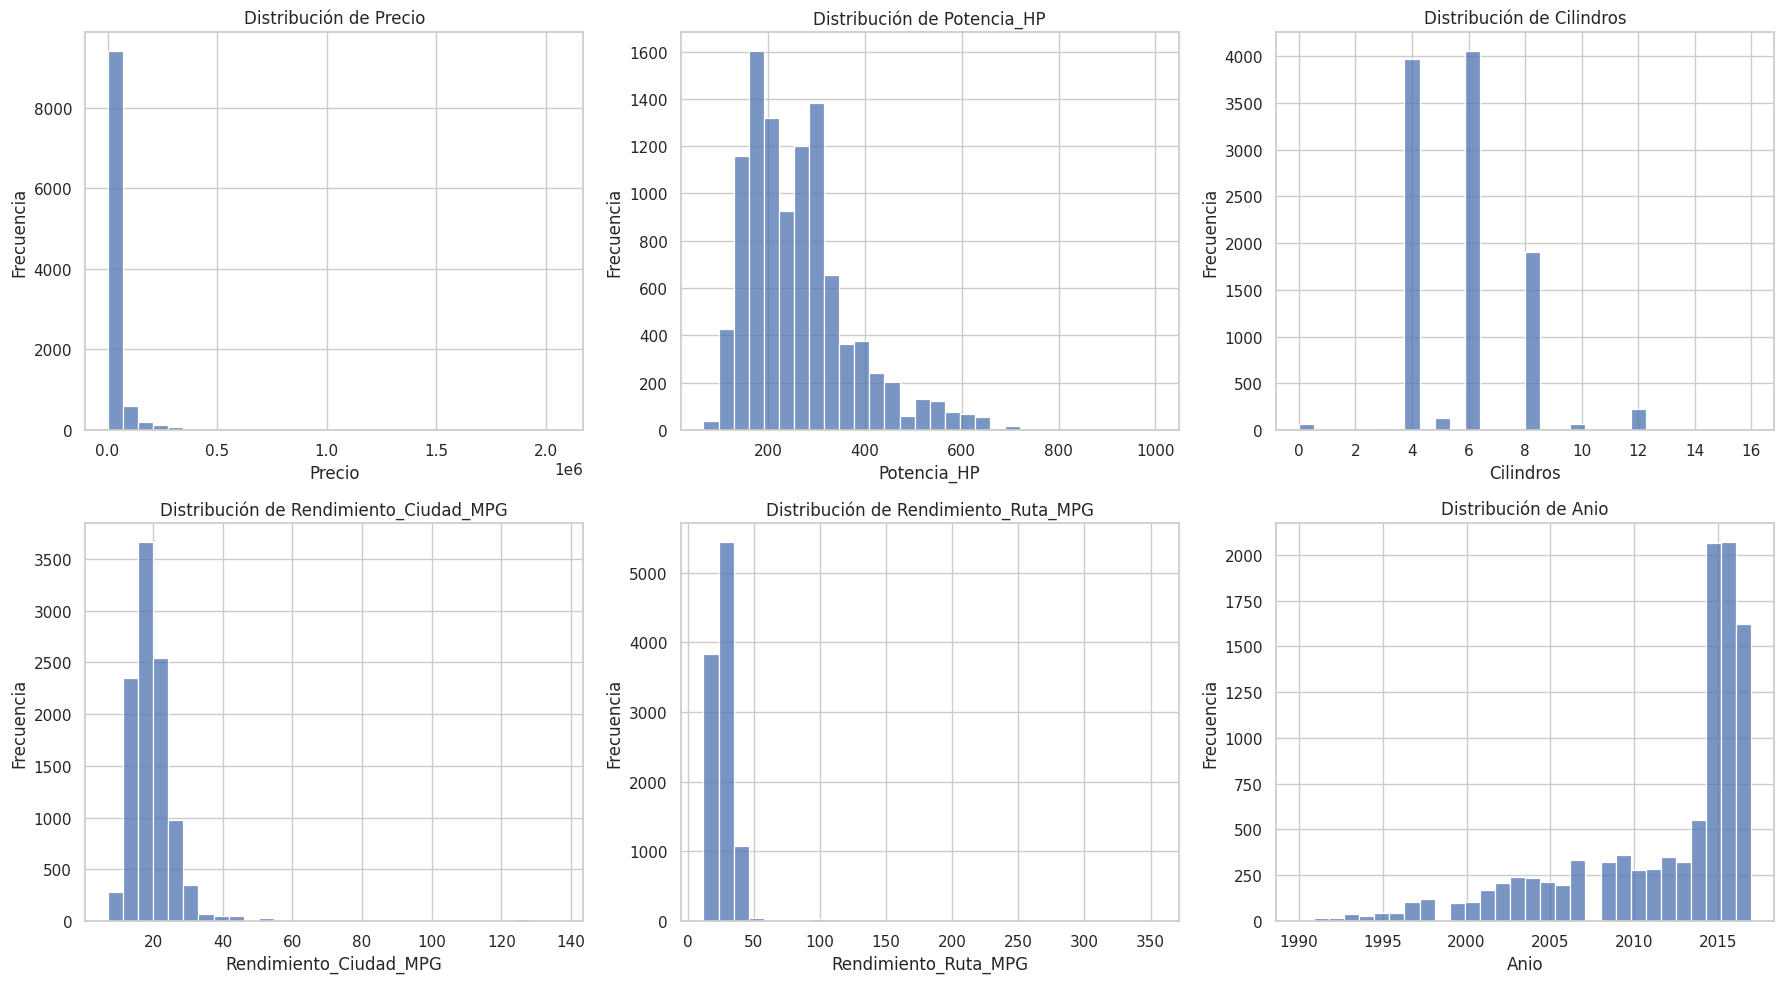

In [33]:
# 2. Histogramas de Distribución
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(columnas_analisis):
    sns.histplot(df_clean[col], ax=axes[i], color='#4C72B0', bins=30)
    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.savefig('histogramas_distribucion.png', dpi=110)
plt.show()

### 2. Interpretación de los Histogramas de Distribución

* **Distribución del Precio:** Se observa una caída abrupta y una cola sumamente larga hacia la derecha. La enorme mayoría de los autos se amontona en el rango inferior a USD 50.000, con muy pocas unidades distribuidas a lo largo del eje del millón y dos millones de dólares.
* **Distribución de Potencia_HP:** Presenta un comportamiento bimodal (dos picos principales). Uno en torno a los 170-200 HP (autos base y de ciudad) y otro cercano a los 300 HP (camionetas, SUVs de gran tamaño y sedanes deportivos).
* **Distribución de Cilindros:** Se comporta de manera multimodal discreta. Los picos más altos corresponden claramente a los motores de 4, 6 y 8 cilindros, que dominan el mercado.
* **Distribución de Rendimiento (Ciudad/Ruta):** Ambas muestran curvas acampanadas, concentradas entre 15 y 30 MPG, con colas derechas muy delgadas debido a los autos eléctricos de altísima eficiencia.
* **Distribución de Anio:** El histograma muestra un crecimiento exponencial hacia los años 2015, 2016 y 2017, lo cual confirma que el dataset cuenta con información mucho más densa e histórica sobre vehículos de la última década del rango que de la década de los 90.


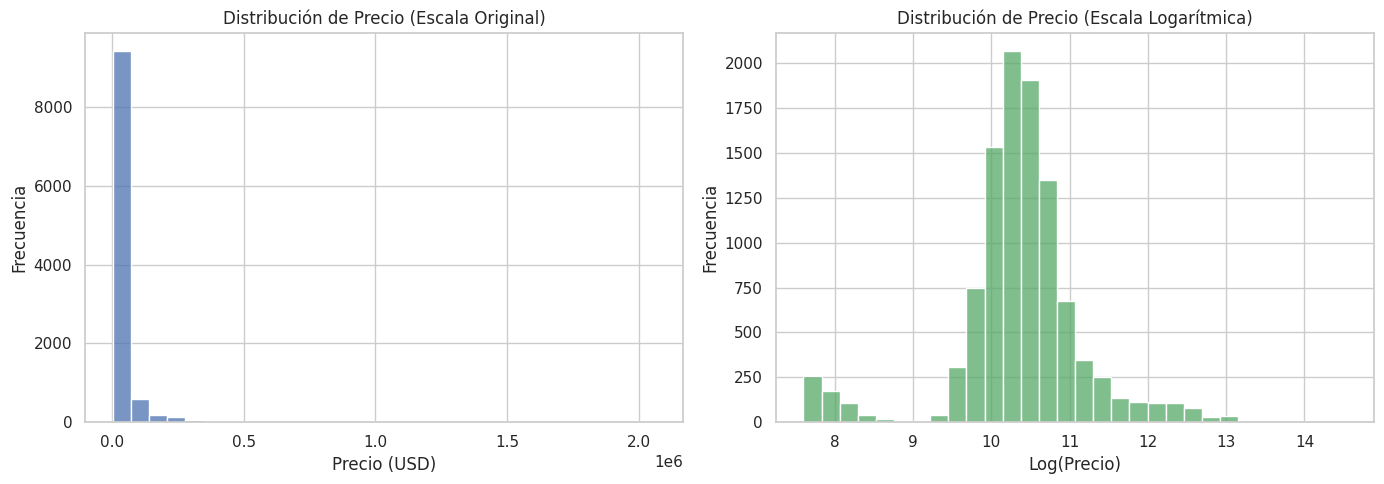

In [34]:
#aca mostrando distribucion pero con precio en escala logaritmica
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma 1: Escala Original
sns.histplot(df_clean['Precio'], ax=axes[0], color='#4C72B0', bins=30)
axes[0].set_title('Distribución de Precio (Escala Original)')
axes[0].set_xlabel('Precio (USD)')
axes[0].set_ylabel('Frecuencia')

# Histograma 2: Escala Logarítmica
# Aplicamos logaritmo a los datos para el eje X
sns.histplot(np.log(df_clean['Precio']), ax=axes[1], color='#55A868', bins=30)
axes[1].set_title('Distribución de Precio (Escala Logarítmica)')
axes[1].set_xlabel('Log(Precio)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.savefig('distribucion_precio_escalas.png', dpi=110)
plt.show()


1)Gráfico de la izquierda: Distribución de Precio (Escala Original)
- Alta asimetría positiva: Los datos presentan un sesgo extremo hacia la derecha. La gran mayoría de los precios están fuertemente concentrados en valores muy bajos (cerca del cero).
- Valores atípicos y compresión: Existe una cola muy larga que se extiende hasta los 2 millones (2.0 × 10⁶), pero hay tan pocos datos en ese rango alto que visualmente solo se aprecia una barra gigante al inicio y una línea plana después. Esto oculta por completo cómo se distribuyen internamente los precios más comunes.

2)Gráfico de la derecha: Distribución de Precio (Escala Logarítmica)
- Distribución aproximadamente normal: Al aplicar el logaritmo al precio, los datos se "estiran" en los valores bajos y se "comprimen" en los altos. Esto revela una forma de campana (gaussiana) en la región central (entre 10 y 11), lo que facilita enormemente el modelado estadístico.
- Presencia de subgrupos o bimodalidad:
	- El pico principal se concentra en torno a un valor logarítmico de 10.3 (que equivale aproximadamente a un precio de $30,000 USD).

	- Se hace visible un pequeño grupo secundario aislado a la izquierda (entre 7.5 y 8.5), que corresponde a un conjunto de productos o bienes con precios notablemente más bajos (alrededor de $1,800 a $5,000 USD) que pasaban totalmente desapercibidos en la escala original.

  Esta transformación es clave en análisis de datos porque convierte una variable altamente sesgada en una distribución mucho más simétrica y manejable, sacando a la luz patrones ocultos y comportamientos de múltiples segmentos de precios.


### Matriz de Correlación

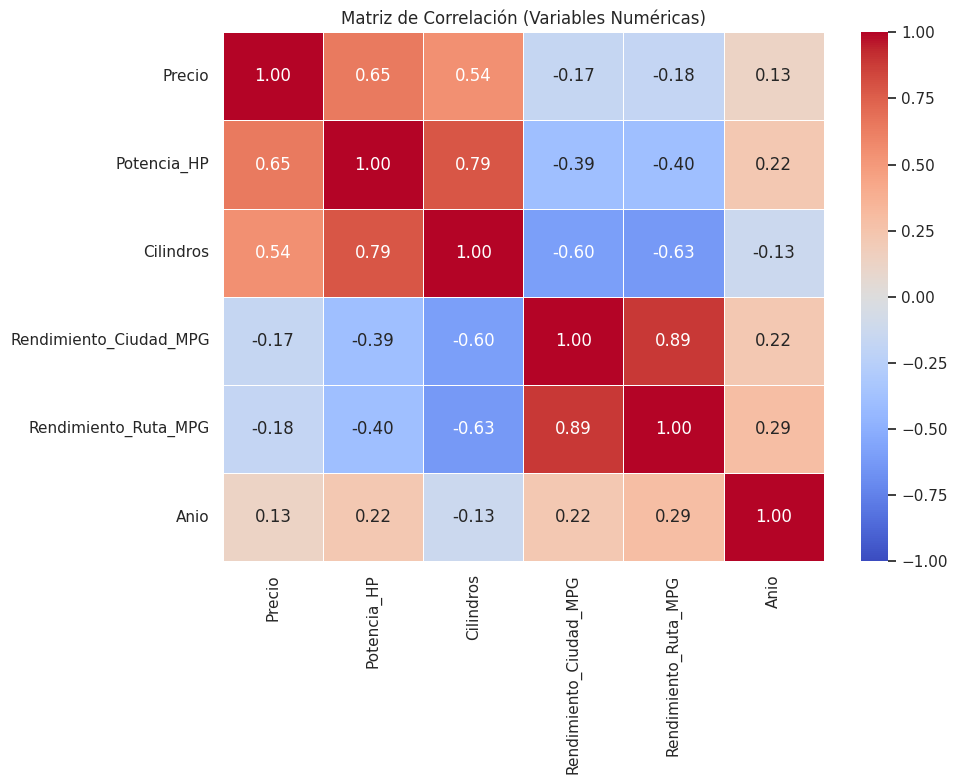

In [35]:
# 3. Matriz de Correlación
matriz_corr = df_clean[columnas_analisis].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriz de Correlación (Variables Numéricas)')
plt.tight_layout()
plt.savefig('matriz_correlacion.png', dpi=110)
plt.show()

### Interpretación de la Matriz de Correlación

* **Potencia_HP vs. Precio ($r = 0.65$):** Es la correlación positiva más fuerte con el target. A medida que aumenta la potencia del motor, el precio del vehículo tiende a incrementarse de manera muy marcada.
* **Cilindros vs. Potencia_HP ($r = 0.79$):** Relación lineal positiva muy fuerte. Es de esperar mecánicamente: más cilindros suelen albergar una cilindrada mayor y, por ende, generar mayor potencia.
* **Cilindros vs. Precio ($r = 0.54$):** Correlación positiva moderada-fuerte. Los motores más grandes están asociados a vehículos de mayor categoría y costo.
* **Rendimiento (Ciudad y Ruta) vs. Cilindros/Potencia ($r \approx -0.40$ a $-0.63$):** Correlación negativa moderada a fuerte. Cuanto más potente es el motor y más cilindros tiene, menor es la eficiencia de combustible (es decir, rinde menos millas por galón, lo cual equivale a un consumo más elevado).
* **Rendimiento_Ciudad vs. Rendimiento_Ruta ($r = 0.89$):** Relación positiva casi perfecta. Un vehículo eficiente en ciudad casi siempre será sumamente eficiente en ruta.
* **Anio vs. Rendimiento / Potencia / Precio ($r \approx 0.13$ a $0.29$):** Existe una correlación positiva leve. Con el paso de los años, los vehículos de fábrica tienden a venir con mejores rendimientos en ruta, potencias ligeramente mayores y precios sugeridos de lista nominalmente más altos.

**¿Hay posible colinealidad?** Sí, en dos pares de variables:
1. **Rendimiento en ciudad y en ruta (r = 0,89):** dicen casi lo mismo. En los modelos se combinan en una sola variable, `Rendimiento_Promedio_MPG`.
2. **Potencia y cilindros (r = 0,79):** la relación es alta pero no perfecta. Se mantienen las dos porque miden cosas distintas del motor, pero lo tendremos en cuenta al interpretar sus coeficientes.

### Gráficos complementarios: relaciones entre variables

En estos gráficos se filtran los autos extremos (más de USD 150.000, más de 500 HP, etc.) **solo para que se lean mejor**. El dataset con el que se modela no se modifica.

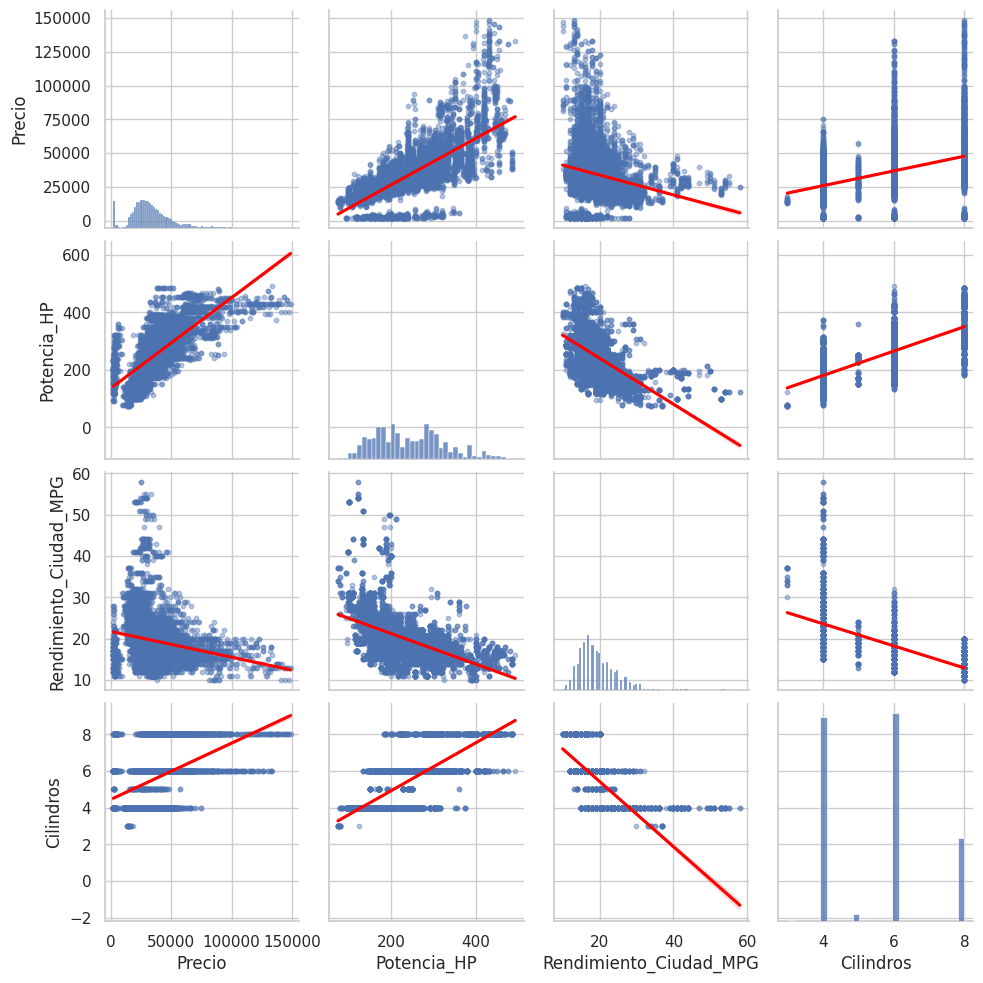

In [36]:
# 1. Filtramos los datos extremos
df_filtrado = df[
    (df['Precio'] > 0) & (df['Precio'] < 150000) &          # Evita los de 2 millones
    (df['Potencia_HP'] > 0) & (df['Potencia_HP'] < 500) &   # Evita los de 1000+ HP
    (df['Cilindros'] >= 3) & (df['Cilindros'] <= 8) &       # Cilindros normales (3 a 8)
    (df['Rendimiento_Ciudad_MPG'] > 0) & (df['Rendimiento_Ciudad_MPG'] < 60)
]

# 2. Graficamos usando el DataFrame limpio
sns.pairplot(
    df_filtrado[['Precio', 'Potencia_HP', 'Rendimiento_Ciudad_MPG', 'Cilindros']],
    kind="reg",
    diag_kind="hist",
    plot_kws={'scatter_kws': {'alpha': 0.4, 's': 10}, 'line_kws': {'color': 'red'}}
)

plt.show()

**1. Diagonales (Distribución Individual)**

- **Precio:** Muestra un sesgo a la derecha muy marcado. Aunque limitamos el análisis a menos de USD 150.000, la gran mayoría de los vehículos se concentra en la franja de menos de USD 40.000, cayendo la frecuencia rápidamente a medida que el valor sube.
- **Potencia_HP:** Presenta una distribución bimodal o de múltiples picos. Hay un gran volumen de vehículos utilitarios/urbanos entre 130 y 200 HP, y un segundo grupo importante de vehículos más deportivos o camionetas entre 280 y 350 HP.
Rendimiento_Ciudad_MPG: Muestra una campana concentrada entre 15 y 25 MPG. Hay una pequeña cola hacia la derecha (vehículos híbridos muy eficientes que rondan las 40-50 MPG).
- **Cilindros:** Al ser una variable discreta, el histograma se presenta en barras verticales limpias correspondientes a 4, 5, 6 y 8 cilindros (con los motores de 4 y 6 cilindros siendo los dominantes absolutos en volumen).

**2. Cruces Clave (Relaciones Bivariadas)**
- **Precio vs. Potencia_HP (Fuerte Relación Positiva):** Se observa una clarísima tendencia ascendente con la línea de regresión apuntando hacia arriba. Los autos de baja potencia (menos de 150 HP) están exclusivamente en el rango de precios bajos. Para acceder a potencias superiores a 300 HP, el piso de precio se eleva significativamente.

- **Rendimiento en Ciudad (MPG) vs. Potencia y Cilindros (Relación Negativa):** Tanto con la Potencia como con los Cilindros, el Rendimiento muestra una curva descendente. A mayor caballaje o mayor cantidad de cilindros, los puntos caen hacia el límite inferior de eficiencia (cerca de 10-15 MPG). Solo los motores más pequeños (3 y 4 cilindros) logran registrar marcas de eficiencia superiores a las 30 MPG.

- **Potencia_HP vs. Cilindros (Estructura Escalonada):** Dado que la cantidad de cilindros es un valor discreto, vemos bandas verticales de puntos. La línea de regresión confirma que a más cilindros, la potencia se incrementa de forma consistente. Sin embargo, también se nota que la dispersión de HP es mayor en los motores de 6 y 8 cilindros que en los de 4.

### Análisis de relaciones entre variables en vehículos de características convencionales.

(el filtro se aplico solo con fines visuales)

/tmp/ipykernel_420/3296541720.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0, 1], data=df_filtrado, x='Cilindros', y='Potencia_HP', palette='Blues')


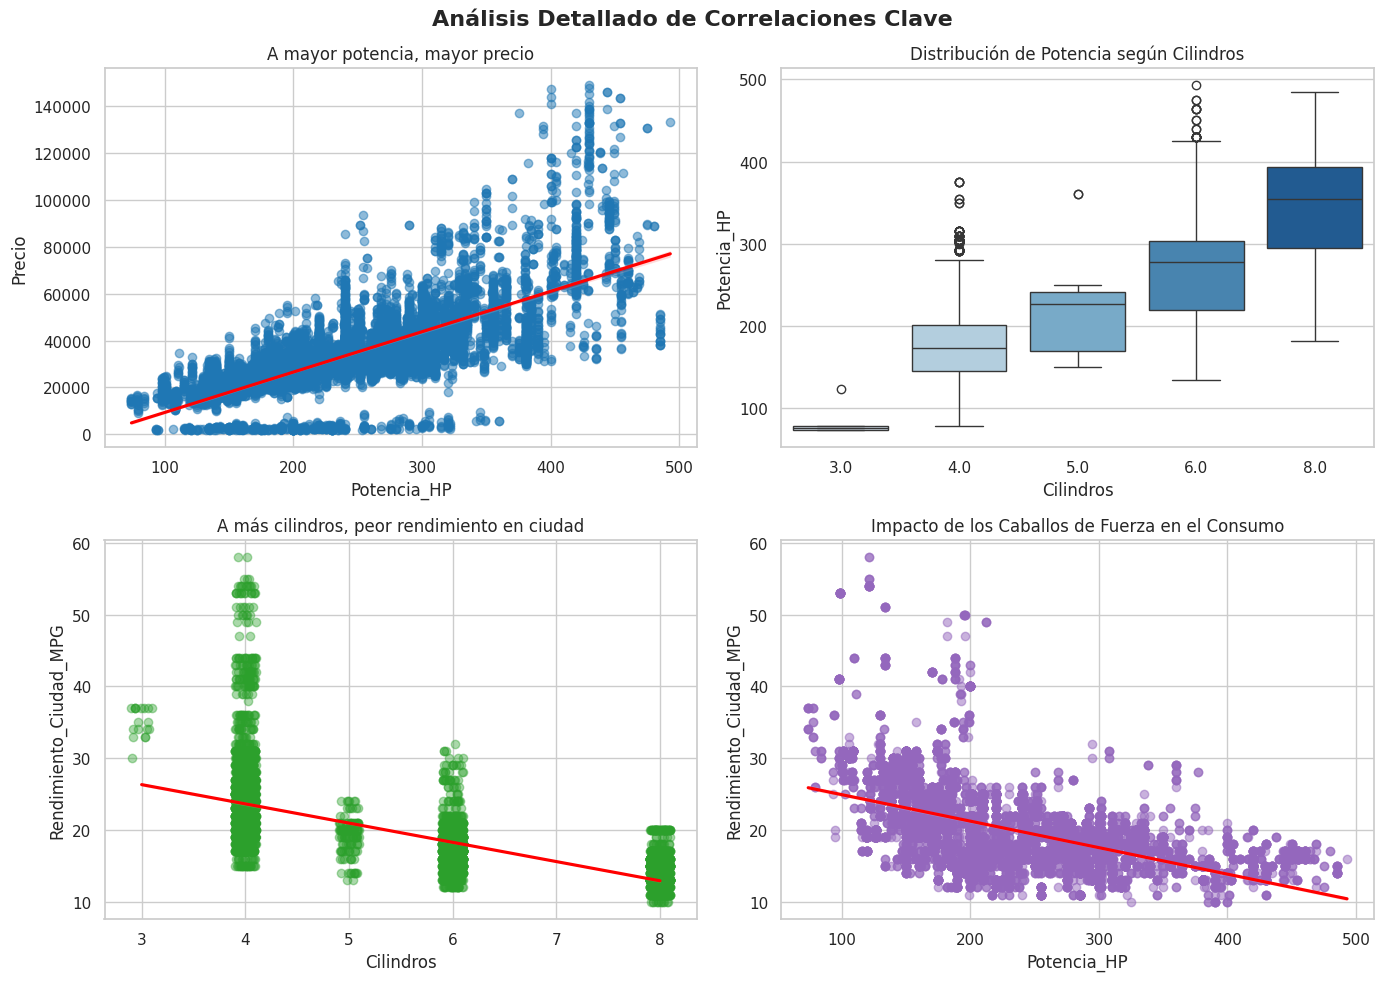

In [37]:
# 1. Limpieza de datos (eliminamos los autos monstruo y errores de escala)
df_filtrado = df[
    (df['Precio'] > 0) & (df['Precio'] < 150000) &
    (df['Potencia_HP'] > 0) & (df['Potencia_HP'] < 500) &
    (df['Cilindros'] >= 3) & (df['Cilindros'] <= 8) &
    (df['Rendimiento_Ciudad_MPG'] > 0) & (df['Rendimiento_Ciudad_MPG'] < 60)
].copy()

# 2. Configuramos una cuadrícula de 2 filas y 2 columnas para los 4 gráficos clave
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Análisis Detallado de Correlaciones Clave', fontsize=16, fontweight='bold')

# Gráfico 1: Precio vs Potencia (Correlación Positiva Alta)
sns.regplot(ax=axes[0, 0], data=df_filtrado, x='Potencia_HP', y='Precio',
            scatter_kws={'alpha':0.5, 'color':'#1f77b4'}, line_kws={'color':'red'})
axes[0, 0].set_title('A mayor potencia, mayor precio')

# Gráfico 2: Potencia vs Cilindros (Correlación Positiva Estructurada)
# Usamos un gráfico de cajas (boxplot) porque Cilindros actúa como categoría
sns.boxplot(ax=axes[0, 1], data=df_filtrado, x='Cilindros', y='Potencia_HP', palette='Blues')
axes[0, 1].set_title('Distribución de Potencia según Cilindros')

# Gráfico 3: Cilindros vs Rendimiento (Correlación Negativa)
sns.regplot(ax=axes[1, 0], data=df_filtrado, x='Cilindros', y='Rendimiento_Ciudad_MPG',
            x_jitter=0.1, scatter_kws={'alpha':0.4, 'color':'#2ca02c'}, line_kws={'color':'red'})
axes[1, 0].set_title('A más cilindros, peor rendimiento en ciudad')

# Gráfico 4: Potencia vs Rendimiento (La regla de oro de los motores)
sns.regplot(ax=axes[1, 1], data=df_filtrado, x='Potencia_HP', y='Rendimiento_Ciudad_MPG',
            scatter_kws={'alpha':0.5, 'color':'#9467bd'}, line_kws={'color':'red'})
axes[1, 1].set_title('Impacto de los Caballos de Fuerza en el Consumo')

# Ajustamos el espacio para que no se superpongan las etiquetas
plt.tight_layout()
plt.show()

1. Superior Izquierda: Potencia (HP) vs. Precio
- Qué muestra: Un gráfico de dispersión con una línea de regresión de pendiente fuertemente positiva.
- Interpretación: Existe una relación lineal positiva directa muy marcada. A medida que incrementamos la potencia del motor (caballos de fuerza), el precio sugerido de venta del vehículo tiende a elevarse de forma constante. Los autos por debajo de los 150 HP se concentran en la base económica (menos de $20,000 USD), mientras que superando los 300 HP es sumamente inusual encontrar opciones económicas, ubicándose casi la totalidad en el segmento premium de precios.

2. Superior Derecha: Distribución de Potencia según Cilindros

- Qué muestra: Un gráfico de cajas (boxplot) ordenado por cantidad de cilindros (3, 4, 5, 6 y 8).

- Interpretación: Físicamente, el número de cilindros determina la estructura del motor. Aquí se ve claramente que a mayor número de cilindros, las cajas se desplazan hacia arriba (mayor rango y mediana de HP). Los autos de 3 cilindros tienen una dispersión de potencia bajísima y casi idéntica, mientras que los motores de 6 y 8 cilindros muestran una gran variedad y dispersión de caballos de fuerza. Esto valida mecánicamente la alta correlación positiva entre ambas características.

3. Inferior Izquierda: Cilindros vs. Rendimiento en Ciudad
- Qué muestra: Un gráfico de dispersión con jitter (pequeña variación para evitar que los puntos discretos de los cilindros se encimen) y una línea de regresión negativa.
- Interpretación: Existe una clara penalización de eficiencia. Los motores con bloques de cilindros más grandes (6 u 8 cilindros) tienen cilindradas mayores, lo que demanda un consumo mucho más elevado de combustible. Esto se traduce visualmente en una caída constante de las millas por galón (MPG) en ciclo urbano. Los autos de 3 y 4 cilindros son los únicos capaces de superar la barrera de las 30-40 MPG.
- **vehículos con mayor número de cilindros tienden a registrar menos millas por galón**

4. Inferior Derecha: Potencia (HP) vs. Rendimiento en Ciudad
- Qué muestra: Un gráfico de dispersión con tendencia de regresión lineal decreciente.
- Interpretación: Representa la "regla de oro" del diseño de motores. Lograr mayor potencia (HP) requiere quemar más mezcla de aire/combustible. Vemos cómo a partir de los 250 HP, el rendimiento en ciudad cae de forma drástica y se estabiliza cerca del piso mínimo de eficiencia (entre 10 y 20 MPG). Es un comportamiento ligeramente curvo (exponencial inverso) que muestra el costo energético de tener un vehículo de alto desempeño.

# ii) Muestreo e Inferencia (Unidad 1)

In [38]:
# 1. Calculamos la cantidad (frecuencia absoluta) de cada Estilo_Vehiculo
conteo_estilos = df_clean['Estilo_Vehiculo'].value_counts()

# 2. Calculamos el porcentaje que representa cada uno del total
porcentaje_estilos = df_clean['Estilo_Vehiculo'].value_counts(normalize=True) * 100

# 3. Consolidamos los datos en un único DataFrame para una presentación prolija
tabla_estilos = pd.DataFrame({
    'Cantidad': conteo_estilos,
    'Porcentaje (%)': porcentaje_estilos
})

# Redondeamos a dos decimales y mostramos los resultados
print("--- DISTRIBUCIÓN POR ESTILO DE VEHÍCULO (Base de Datos Limpia) ---")
display(tabla_estilos.round(2))

--- DISTRIBUCIÓN POR ESTILO DE VEHÍCULO (Base de Datos Limpia) ---


,Cantidad,Porcentaje (%)
Estilo_Vehiculo,,
Sedan,2619,25.07
SUV 4 puertas,2418,23.15
Coupe,1073,10.27
Convertible,714,6.83
Pickup Cabina Doble,654,6.26
Hatchback 4 puertas,623,5.96
Pickup Cabina Extendida,579,5.54
Familiar (Wagon),488,4.67
Minivan de Pasajeros,352,3.37


**Análisis:** el mercado está dominado por los **sedanes (25 %)** y los **SUV de 4 puertas (23 %)**. Hay estilos muy poco frecuentes, como el SUV convertible (0,17 %, 18 autos) o la minivan de carga (0,5 %). Con un muestreo aleatorio simple de 750 autos, esos estilos podrían no aparecer; por eso se usa un **muestreo estratificado por estilo**, que garantiza que cada estilo esté representado en la misma proporción que en la población.

elegimos este para representar diferentes tipos de automóviles.

In [39]:
from sklearn.model_selection import train_test_split

# Extraemos la muestra estratificada de 750 observaciones
muestra_750, _ = train_test_split(
    df,
    train_size=750,
    stratify=df['Estilo_Vehiculo'],
    random_state=42 # Fijamos la semilla para que los resultados sean reproducibles
)

#print("aaaaa",muestra_750)

# Calculamos las métricas para validar la representatividad
media_pob = df['Precio'].mean()
var_pob = df['Precio'].var()
desv_pob = df["Precio"].std()

media_mues = muestra_750['Precio'].mean()
var_mues = muestra_750['Precio'].var()
desv_mues = muestra_750["Precio"].std()

# Mostramos los resultados
print("=== VALIDACIÓN DE LA MUESTRA ===")
print(f"Población Total ({len(df)} obs):")
print(f" - Media del Precio: ${media_pob:.2f}")
print(f" - Varianza del Precio: {var_pob:.2f}")
print(f" - Desviación Estándar del Precio: {desv_pob:.2f}\n")

print(f"Muestra Estratificada (750 obs):")
print(f" - Media del Precio: ${media_mues:.2f}")
print(f" - Varianza del Precio: {var_mues:.2f}")
print(f" - Desviación Estándar del Precio: {desv_mues:.2f}")

# Comprobación de proporciones de una categoría al azar para demostrar
print("\nVerificación de estratificación (Proporción de Sedanes):")
print(f"Población: {(df['Estilo_Vehiculo'] == 'Sedan').mean():.3f}")
print(f"Muestra:   {(muestra_750['Estilo_Vehiculo'] == 'Sedan').mean():.3f}")

=== VALIDACIÓN DE LA MUESTRA ===
Población Total (10447 obs):
 - Media del Precio: $44788.67
 - Varianza del Precio: 3936768555.63
 - Desviación Estándar del Precio: 62743.67

Muestra Estratificada (750 obs):
 - Media del Precio: $44195.16
 - Varianza del Precio: 2764539346.38
 - Desviación Estándar del Precio: 52578.89

Verificación de estratificación (Proporción de Sedanes):
Población: 0.251
Muestra:   0.251


In [40]:
comparacion = pd.DataFrame({
    'Población': df['Precio'].describe(),
    'Muestra': muestra_750['Precio'].describe()
})

display(comparacion.round(2))

,Población,Muestra
count,10447.00,750.00
mean,44788.67,44195.16
std,62743.67,52578.89
min,2002.00,2032.00
25%,23515.00,22901.25
50%,31870.00,30995.00
75%,44200.00,44462.50
max,2065902.00,492425.00


### Analisis de representatividad de la muestra

Al comparar las estadísticas de la población con las de la muestra estratificada de 750 observaciones, observamos que **la media del precio es muy similar** en ambos conjuntos. Sin embargo, la **varianza de la muestra es aproximadamente un 30% menor**, mientras que la desviación estándar disminuye de 62.743 a $52.579.

### ¿Por qué ocurre esto?

Una posible explicación es la presencia de **valores atípicos extremos en la población**. Mientras que el vehículo más caro de la base completa alcanza los **$$2.065.902**, el precio máximo de la muestra es de **$492.425**.

La distribución de precios presenta una marcada asimetría positiva (cola hacia la derecha), debido a la existencia de un pequeño grupo de vehículos de lujo y alto rendimiento con precios muy superiores al resto.

Esto tiene dos consecuencias:

- **Baja representación de valores extremos:** al seleccionar únicamente 750 observaciones de una población de 10.447, es posible que los vehículos con precios excepcionalmente elevados no sean incluidos en la muestra.

### Conclusión

El muestreo se realizó mediante **estratificación por estilo de vehículo**, lo que permite conservar aproximadamente las proporciones de sedanes, SUV, coupés y demás categorías.

de todas maneras, esta técnica no garantiza reproducir exactamente la distribución de precios dentro de cada estilo.

Por lo tanto, **la muestra presenta una buena aproximación a las medidas centrales de la población, pero una menor representación de los precios extremos**, lo que explica plausiblemente la diferencia observada en la varianza.

Este hallazgo será importante al comparar posteriormente los resultados de la regresión lineal obtenidos con la muestra y con la base completa.

In [41]:
# Prueba alternativa: estratificar por PRECIO en lugar de por estilo.
# Se divide el precio en 5 tramos con la misma cantidad de autos (quintiles) y se toma la muestra
# respetando esos tramos. Se usa una serie aparte para no agregar columnas al dataset.
estrato_precio = pd.qcut(df["Precio"], q=5, labels=False, duplicates="drop")

muestra_precio, _ = train_test_split(
    df,
    train_size=750,
    stratify=estrato_precio,
    random_state=42
)

comparacion2 = pd.DataFrame({
    'Población': df['Precio'].describe(),
    'Muestra por estilo': muestra_750['Precio'].describe(),
    'Muestra por precio': muestra_precio['Precio'].describe()
})

display(comparacion2.round(2))

,Población,Muestra por estilo,Muestra por precio
count,10447.00,750.00,750.00
mean,44788.67,44195.16,45243.55
std,62743.67,52578.89,76186.34
min,2002.00,2032.00,2003.00
25%,23515.00,22901.25,23724.00
50%,31870.00,30995.00,31962.50
75%,44200.00,44462.50,45406.25
max,2065902.00,492425.00,1705769.00


In [42]:
# Como el precio está muy sesgado, se compara también en escala logarítmica (la escala que usa el modelo)
log_comp = pd.DataFrame({
    "Media log(Precio)": [np.log(df["Precio"]).mean(), np.log(muestra_750["Precio"]).mean(), np.log(muestra_precio["Precio"]).mean()],
    "Varianza log(Precio)": [np.log(df["Precio"]).var(), np.log(muestra_750["Precio"]).var(), np.log(muestra_precio["Precio"]).var()],
    "Autos de más de USD 500.000": [(df["Precio"] > 500000).sum(), (muestra_750["Precio"] > 500000).sum(), (muestra_precio["Precio"] > 500000).sum()],
}, index=["Población", "Muestra por estilo", "Muestra por precio"])
display(log_comp.round(4))

,Media log(Precio),Varianza log(Precio),Autos de más de USD 500.000
Población,10.3560,0.7029,11
Muestra por estilo,10.3544,0.6764,0
Muestra por precio,10.3481,0.7329,1


Debido a la diferencia observada entre la varianza de la población y la muestra estratificada por estilo de vehículo, se realizó una prueba alternativa utilizando una estratificación por  precio.

vemos q ambas estrategias permiten obtener medias y medianas similares a las de la población. Sin embargo, presentan diferencias importantes en su dispersión: la muestra por estilo tiene una varianza menor, mientras que la muestra por precio presenta una varianza mayor.

Esta diferencia se relaciona con la presencia de vehículos de precios extremadamente elevados. La muestra por estilo no incorporó vehículos superiores a USD 500.000, mientras que la muestra por precio incluyó uno.

Adicionalmente, al comparar la distribución del logaritmo del precio, se observaron varianzas considerablemente más similares entre ambas muestras y la población.

ninguna estrategia garantiza reproducir exactamente todas las características de la población

**Decisión:** se mantiene la **muestra estratificada por estilo**. Representa bien la estructura del mercado (permite preservar aproximadamente la composición de las diferentes categorías de automóviles). Estratificar por precio usaría la propia variable que se quiere explicar para armar la muestra.

----------------------------------------------------

# iii) Modelado Estadístico Clásico: Regresión Lineal Múltiple (Unidades 3, 4 y 5)

Primero se ajusta el modelo con la muestra de $n = 750$ y después se repite con la base completa ($N = 10.447$). Preparación de los datos:
* Transformación logarítmica del `Precio`, para reducir el impacto de los outliers y el sesgo.
* Variables *dummy* para las variables categóricas principales.
* Selección de variables numéricas para evitar la multicolinealidad.

1) **Transformación Logarítmica del Target:** Dado que la variable Precio presenta un fuerte sesgo a la derecha y outliers de alta gama, aplicaremos elogaritmo natural $\log(\text{Precio})$. Esta transformación permite reducir las grandes diferencias entre los precios, disminuyendo el peso relativo de los valores extremos sin necesidad de eliminarlos. De esta manera, se busca obtener una distribución más equilibrada y facilitar el ajuste del modelo de regresión lineal.

2) **Codificación One-Hot (Variables Dummy):** Convertiremos las variables cualitativas clave en variables binarias (0 o 1). Usaremos Tipo_Combustible, Tipo_Transmision, Traccion y Tamanio_Vehiculo para no sobrecargar el modelo con demasiada cardinalidad (evitando por ahora Marca y Modelo que tienen cientos de valores distintos, garantizando la parsimonia).

3) **Tratamiento de la Colinealidad:** En lugar de incluir Rendimiento_Ciudad_MPG y Rendimiento_Ruta_MPG juntas (que tienen correlación de 0.89), usaremos un promedio ponderado o simplemente una de ellas (por ejemplo, el rendimiento en ruta o el consumo promedio) para evitar la multicolinealidad.



In [43]:
#Recentrado del año: a partir de acá, "Anio" pasa a medir "años desde 1990"
#(1990 -> 0, 1991 -> 1, ..., 2017 -> 27). Solo se aplica a los datos de los modelos.
#El "if" evita que se reste dos veces si se ejecuta la celda de nuevo.
if df_clean["Anio"].max() > 1000:
    df_clean["Anio"] = df_clean["Anio"] - 1990
if muestra_750["Anio"].max() > 1000:
    muestra_750["Anio"] = muestra_750["Anio"] - 1990

print("Rango de Anio en la base completa:", df_clean["Anio"].min(), "a", df_clean["Anio"].max())
print("Rango de Anio en la muestra:", muestra_750["Anio"].min(), "a", muestra_750["Anio"].max())

Rango de Anio en la base completa: 0 a 27
Rango de Anio en la muestra: 0 a 27


**Recentrado de la variable año:** a partir de esta sección, Anio se expresa como años desde 1990 (1990 → 0, 2017 → 27). Es la misma información con otra escala.

**¿Por qué?** Con el año original (valores cercanos a 2000), statsmodels mostraba un aviso de "condition number" muy alto (alrededor de 1.000.000), que sugiere multicolinealidad, y la constante daba −119, que representa el precio de un auto del "año 0" y no tiene sentido. El año es un número enorme y casi constante en proporción a su tamaño (2000 ± 14), así que se parece mucho a la columna de la constante.

Al recentrar el año:
- El coeficiente del año, el $R^2$ y todas las demás variables quedan exactamente iguales. Un año más sigue sumando un 6,6 % al precio.
- El número de condición baja de alrededor de 1.000.000 a alrededor de 30.000, y la constante pasa a un valor razonable (cerca de 8).

Esto demuestra que el aviso se debía a la escala del año y no a un problema real de colinealidad. El aviso no desaparece del todo porque Potencia_HP también está en una escala grande (66 a 1.001 HP) comparada con las dummies (0 o 1), pero ese caso es igual de inofensivo.

In [44]:
import statsmodels.api as sm
import pandas as pd
import numpy as np

# 1. Creamos una copia de trabajo de nuestra muestra para no alterar la original
data_modelo = muestra_750.copy()

# 2. Aplicamos la transformación logarítmica a la variable objetivo (target)
data_modelo['Log_Precio'] = np.log(data_modelo['Precio'])

# 3. Tratamiento de multicolinealidad en rendimientos:
# Creamos una única variable de 'Rendimiento_Promedio_MPG' combinando ambas proporcionalmente
data_modelo['Rendimiento_Promedio_MPG'] = 0.55 * data_modelo['Rendimiento_Ciudad_MPG'] + 0.45 * data_modelo['Rendimiento_Ruta_MPG']

# 4. Selección de variables para el modelo
# Variables numéricas explicativas
var_numericas = ['Potencia_HP', 'Cilindros', 'Rendimiento_Promedio_MPG', 'Anio', 'Puertas']

# Variables categóricas a convertir en dummies
var_categoricas = ['Tipo_Combustible', 'Tipo_Transmision', 'Traccion', 'Tamanio_Vehiculo']

# 5. Generación de variables Dummy (evitando la trampa de la multicolinealidad con drop_first=True)
dummies = pd.get_dummies(data_modelo[var_categoricas], drop_first=True, dtype=int)

# 6. Consolidamos el set de predictores (X) y la variable dependiente (y)
X = pd.concat([data_modelo[var_numericas], dummies], axis=1)
y = data_modelo['Log_Precio']

# Agregamos la constante (intercepto) requerida por statsmodels
X_con_constante = sm.add_constant(X)

# 7. Ajustamos el modelo de Regresión Lineal Múltiple por Mínimos Cuadrados Ordinarios (OLS)
modelo_ols = sm.OLS(y, X_con_constante).fit()

# 8. Mostramos el resumen estadístico completo
print(modelo_ols.summary())

                            OLS Regression Results                            
Dep. Variable:             Log_Precio   R-squared:                       0.711
Model:                            OLS   Adj. R-squared:                  0.705
Method:                 Least Squares   F-statistic:                     106.1
Date:                Mon, 16 Nov 2026   Prob (F-statistic):          3.14e-184
Time:                        02:37:04   Log-Likelihood:                -451.12
No. Observations:                 750   AIC:                             938.2
Df Residuals:                     732   BIC:                             1021.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


/tmp/ipykernel_420/3208075322.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo_ols = sm.OLS(y, X_con_constante).fit()


• Poder explicativo: El modelo explica el 70.5% de la variabilidad del logaritmo del precio (R² ajustado = 0,705), y es estadísticamente significativo en su conjunto (Prob (F-statistic) = 3.14e-184).

• Interpretación logarítmica: Al estar la variable dependiente en escala logarítmica (Log_Precio), los coeficientes representan aproximadamente cambios porcentuales en el precio del vehículo (por ejemplo, cada año más nuevo aumenta el precio en cerca de un 6.5%).

Aca notamos que las variables dummy Tipo_Transmision_TRANSMISION_DIRECTA y Tipo_Combustible_electrico tenian el mismo valor de coeficiente, por lo que pensamos que generaba colinealidad

Esta sospecha se ve reforzada por las advertencias de statsmodels, que indican que la matriz de variables explicativas no tiene rango completo y que algunos coeficientes no pueden estimarse de manera única.

Por este motivo, se decidió investigar la relación entre ambas variables y corregir las posibles redundancias antes de continuar con la interpretación del modelo.

In [45]:
pd.crosstab(
    muestra_750["Tipo_Combustible"],
    muestra_750["Tipo_Transmision"]
)

Tipo_Transmision,AUTOMATICA,MANUAL,MANUAL_AUTOMATIZADA,TRANSMISION_DIRECTA
Tipo_Combustible,,,,
diesel,10,4,3,0
electrico,0,0,0,7
flex-fuel,71,4,1,0
gas natural,1,0,0,0
nafta comun,328,95,1,0
nafta premium,145,51,29,0


existe multicolinealidad perfecta entre ambas variables dummy.

- Los 7 vehículos eléctricos tienen transmisión directa.
- Ningún vehículo de otro combustible tiene transmisión directa.
- Ningún eléctrico tiene otro tipo de transmisión.

Por lo tanto, ambas columnas dummy son idénticas (tienen exactamente los mismos 0 y 1).

In [46]:


# 1. Creamos una copia de trabajo de nuestra muestra para no alterar la original
data_modelo = muestra_750.copy()

# 2. Aplicamos la transformación logarítmica a la variable objetivo (target)
data_modelo['Log_Precio'] = np.log(data_modelo['Precio'])

# 3. Tratamiento de multicolinealidad en rendimientos:
# Creamos una única variable de 'Rendimiento_Promedio_MPG' combinando ambas proporcionalmente
data_modelo['Rendimiento_Promedio_MPG'] = 0.55 * data_modelo['Rendimiento_Ciudad_MPG'] + 0.45 * data_modelo['Rendimiento_Ruta_MPG']

# 4. Selección de variables para el modelo
# Variables numéricas explicativas
var_numericas = ['Potencia_HP', 'Cilindros', 'Rendimiento_Promedio_MPG', 'Anio', 'Puertas']

# Variables categóricas a convertir en dummies
var_categoricas = ['Tipo_Combustible', 'Tipo_Transmision', 'Traccion', 'Tamanio_Vehiculo']

# 5. Generación de variables Dummy (evitando la trampa de la multicolinealidad con drop_first=True)
dummies = pd.get_dummies(data_modelo[var_categoricas], drop_first=True, dtype=int)

# 5b. Colinealidad perfecta: en esta muestra TODOS los autos eléctricos tienen transmisión directa
# (y ningún otro auto la tiene), así que las dos dummies son columnas idénticas. Con dos columnas
# idénticas, OLS no puede separar el efecto de cada una. Se elimina una: el efecto queda en 'electrico'.
if "Tipo_Transmision_TRANSMISION_DIRECTA" in dummies and (dummies["Tipo_Transmision_TRANSMISION_DIRECTA"] == dummies["Tipo_Combustible_electrico"]).all():
    dummies = dummies.drop(columns="Tipo_Transmision_TRANSMISION_DIRECTA")
    print("Se eliminó Tipo_Transmision_TRANSMISION_DIRECTA (idéntica a Tipo_Combustible_electrico en la muestra)\n")

# 6. Consolidamos el set de predictores (X) y la variable dependiente (y)
X = pd.concat([data_modelo[var_numericas], dummies], axis=1)
y = data_modelo['Log_Precio']

# Agregamos la constante (intercepto) requerida por statsmodels
X_con_constante = sm.add_constant(X)

# 7. Ajustamos el modelo de Regresión Lineal Múltiple por Mínimos Cuadrados Ordinarios (OLS)
modelo_ols = sm.OLS(y, X_con_constante).fit()

# 8. Mostramos el resumen estadístico completo
print(modelo_ols.summary())

Se eliminó Tipo_Transmision_TRANSMISION_DIRECTA (idéntica a Tipo_Combustible_electrico en la muestra)

                            OLS Regression Results                            
Dep. Variable:             Log_Precio   R-squared:                       0.711
Model:                            OLS   Adj. R-squared:                  0.705
Method:                 Least Squares   F-statistic:                     106.1
Date:                Mon, 16 Nov 2026   Prob (F-statistic):          3.14e-184
Time:                        02:37:05   Log-Likelihood:                -451.12
No. Observations:                 750   AIC:                             938.2
Df Residuals:                     732   BIC:                             1021.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--

**Análisis del modelo con la muestra (n = 750):**
- El modelo es **globalmente significativo** (Prob F ≈ 3e-184 < 0,05) y explica el **70,5 %** de la variabilidad del log del precio ($R^2$ ajustado = 0,705).
- Son significativas al 5 %: potencia, cilindros, año, transmisión manual, combustibles flex-fuel, nafta común y eléctrico, tracción integral y tamaño. No son significativas: rendimiento (p = 0,091), puertas, nafta premium, transmisión manual automatizada, gas natural y tracción delantera y trasera.
- **Colinealidad perfecta corregida:** en esta muestra, todos los autos eléctricos tienen transmisión directa y ningún otro auto la tiene, así que esas dos dummies eran columnas idénticas. En ese caso, el modelo no puede separar el efecto de cada una (statsmodels lo avisaba con un "smallest eigenvalue" casi cero). Se eliminó `Tipo_Transmision_TRANSMISION_DIRECTA`, y su efecto queda incluido en `Tipo_Combustible_electrico`.
- El aviso de "Cond. No." que todavía aparece se debe a la diferencia de escala entre Potencia_HP (cientos de HP) y las dummies (0 o 1), no a colinealidad entre variables. Gracias al recentrado del año, el número bajó de alrededor de 1.000.000 a alrededor de 8.000, y la constante (≈ 8,28) ya no da un valor absurdo.


## Regresión Lineal Múltiple sobre la Base de Datos Completa

A continuación, replicamos la misma estructura de preparación y modelado de regresión lineal múltiple, pero utilizando la totalidad de las observaciones limpias ($N = 10.447$).


In [47]:
# 1. Creamos una copia de trabajo de la base completa limpia
data_modelo_completo = df_clean.copy()

# 2. Aplicamos la transformación logarítmica al Precio (target)
data_modelo_completo['Log_Precio'] = np.log(data_modelo_completo['Precio'])

# 3. Tratamiento de la colinealidad en rendimientos
data_modelo_completo['Rendimiento_Promedio_MPG'] = 0.55 * data_modelo_completo['Rendimiento_Ciudad_MPG'] + 0.45 * data_modelo_completo['Rendimiento_Ruta_MPG']

# 4. Selección de variables
var_numericas = ['Potencia_HP', 'Cilindros', 'Rendimiento_Promedio_MPG', 'Anio', 'Puertas']
var_categoricas = ['Tipo_Combustible', 'Tipo_Transmision', 'Traccion', 'Tamanio_Vehiculo']

# 5. Generación de variables Dummy (con drop_first=True para evitar la trampa de colinealidad)
dummies_completo = pd.get_dummies(
    data_modelo_completo[var_categoricas],
    drop_first=True,
    dtype=int
)
# Eliminamos la misma columna que en la muestra
dummies_completo = dummies_completo.drop(
    columns=["Tipo_Transmision_TRANSMISION_DIRECTA"]
)

# 6. Consolidamos predictores (X) y target (y)
X_completo = pd.concat([data_modelo_completo[var_numericas], dummies_completo], axis=1)
y_completo = data_modelo_completo['Log_Precio']

# Agregamos la constante
X_completo_const = sm.add_constant(X_completo)

# 7. Ajustamos el modelo por Mínimos Cuadrados Ordinarios (OLS)
modelo_completo_ols = sm.OLS(y_completo, X_completo_const).fit()

# 8. Visualizamos el reporte estadístico de la base completa
print(modelo_completo_ols.summary())

                            OLS Regression Results                            
Dep. Variable:             Log_Precio   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                     1440.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:37:05   Log-Likelihood:                -6458.1
No. Observations:               10447   AIC:                         1.295e+04
Df Residuals:                   10428   BIC:                         1.309e+04
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


## Comparación: Muestra (n = 750) vs. Población Completa (N = 10.447)

### 1. Bondad de ajuste (R² ajustado)

- El R² ajustado se mantiene estable: **0,705 en la muestra y 0,713 en la base completa**.
- Un modelo estimado con solo el 7,2% de los datos logra explicar prácticamente la misma proporción de la variabilidad del **logaritmo del precio** que el modelo ajustado con todos los registros.

### 2. Precisión de las estimaciones: errores estándar

- Con 10.447 observaciones, los **errores estándar disminuyen considerablemente** en las variables principales. Por ejemplo, el de `Potencia_HP` baja de aproximadamente 0,00036 a 0,0000979, y el de `Anio`, de 0,0042 a aproximadamente 0,0011.
- Esto coincide con lo esperado teóricamente: bajo condiciones comparables, el error estándar tiende a disminuir aproximadamente en proporción a \(1/\sqrt{n}\). Como la base completa es unas 14 veces más grande, el error estándar podría reducirse por un factor cercano a \(\sqrt{14}\approx3,7\). En consecuencia, los intervalos de confianza de los principales coeficientes se vuelven más estrechos.

### 3. Estabilidad de los coeficientes

Como la variable objetivo está expresada en logaritmos, los coeficientes pueden interpretarse como cambios porcentuales en el precio mediante la fórmula \((e^\beta-1)\times100\), manteniendo constantes las demás variables.

Los coeficientes principales conservan su signo y presentan magnitudes relativamente similares:

- **Potencia:** cada HP adicional se asocia con un precio aproximadamente **0,23% mayor** en la muestra y **0,29% mayor** en la base completa.
- **Cilindros:** cada cilindro adicional se asocia con un precio **13,0% mayor** en la muestra y **10,5% mayor** en la base completa.
- **Año:** cada año más reciente se asocia con un precio **6,5% mayor** en la muestra y **6,6% mayor** en la base completa.
- **Transmisión manual:** se asocia con un precio aproximadamente **20,9% menor** en la muestra y **22,0% menor** en la base completa, respecto de la transmisión automática (categoría de referencia).

### 4. Impacto del tamaño de la muestra en la significatividad (p-valores)

- **`Rendimiento_Promedio_MPG`:** en la muestra, el coeficiente es −0,0084 con p = 0,091, por lo que **no resulta estadísticamente significativo al 5%**. En la base completa, el coeficiente es −0,0066 con p inferior a 0,001, por lo que resulta altamente significativo. Esto sugiere que, con 750 observaciones, la precisión de la estimación no era suficiente para identificar estadísticamente un efecto de esa magnitud, mientras que con la base completa sí se logra.
- **Variables de combustible y tracción:** `Tipo_Combustible_nafta premium` (p = 0,588) y `Traccion_traccion delantera` (p = 0,087) no eran significativas en la muestra, pero pasan a serlo en la base completa, con p = 0,007 y p < 0,001, respectivamente
- **Conclusión:** el aumento del tamaño muestral permite estimaciones más precisas y facilita la detección de efectos pequeños. Un p-valor no significativo en una muestra reducida no demuestra que una variable carezca de relación con el precio; también puede deberse a la menor precisión de su estimación.

### Conclusión general

**Pasar de 750 a 10.447 observaciones no produjo una mejora importante en el R² ajustado, pero sí una reducción considerable de los errores estándar y cambios en la significatividad estadística de varias variables.**

Esto demuestra que, aunque una muestra relativamente pequeña puede obtener un ajuste similar al de la base completa, disponer de más observaciones permite estimar los coeficientes con mayor precisión y detectar relaciones que inicialmente no resultaban estadísticamente significativas.

## Justificación Metodológica: Selección y Exclusión de Variables

Para garantizar la validez, parsimonia e interpretabilidad de los modelos de regresión lineal múltiple, la selección de variables no se realizó al azar, sino siguiendo criterios estadísticos, mecánicos y de modelado predictivo.

### 1. Variables Seleccionadas (Predictores Incluidos)

*   **`Potencia_HP` y `Cilindros`:** Son los dos indicadores de rendimiento mecánico más importantes de un automóvil. Como demostramos en el *Estudio Analítico Descriptivo*, la potencia tiene la correlación lineal más alta con el precio ($r = 0.65$).
*   **`Anio`:** Permite capturar diferencias de precio asociadas al año del modelo y a la evolución tecnológica.a. Su inclusión es vital dado que el rango de datos es muy amplio (1990-2017).
*   **`Rendimiento_Promedio_MPG`:** Se diseñó como un indicador consolidado (promedio ponderado del consumo en ciudad y ruta) para representar la eficiencia energética del vehículo, un factor crecientemente valorado en el mercado.
*   **`Puertas`:** Funciona como un proxy de la configuración de carrocería (sedanes/SUVs vs. coupés/deportivos de dos puertas).
*   **Variables Categóricas Principales (`Tipo_Combustible`, `Tipo_Transmision`, `Traccion`, `Tamanio_Vehiculo`):** Aportan información cualitativa estructural crucial (por ejemplo, si es automático o manual, si es tracción integral, o si es un vehículo grande o eléctrico) sin inflar excesivamente el número de coeficientes.

---

### 2. Variables Excluidas (¿Por qué quedaron fuera?)

La exclusión de ciertas variables es tan importante como la selección para evitar problemas graves de estimación:

*   **`Marca` y `Modelo` (Excluidas por Alta Cardinalidad):**
    *   *Razón:* `Marca` tiene 48 categorías únicas y `Modelo` posee más de 900. Si creáramos variables *dummy* para estas características, estaríamos agregando cientos de columnas nuevas al modelo de regresión.
    *   *Consecuencia de incluirlas:* Esto destruiría la **parsimonia** del modelo, causaría sobreajuste (*overfitting*), y en la muestra de $n=750$ provocaría que muchas categorías se quedaran con 1 o 0 observaciones, haciendo que la matriz de diseño fuera matemáticamente singular o inestable (imposible de estimar de forma confiable).
*   **`Rendimiento_Ciudad_MPG` y `Rendimiento_Ruta_MPG` por separado (Excluidas por Multicolinealidad):**
    *   *Razón:* Poseen una correlación positiva casi perfecta de **0.89**.
    *   *Consecuencia de incluirlas:* Incluir ambas en el mismo modelo provoca **riesgo de multicolinealidad**. Esto incrementa artificialmente los errores estándar de los coeficientes, haciendo que las estimaciones sean inestables, cambien bruscamente de signo ante mínimos cambios en los datos, y pierdan su significatividad estadística individual.
*   **`Popularidad` (Excluida por Redundancia y Anacronismo):**
    *   *Razón:* Es constante para cada marca (tiene solo 48 valores únicos) y mide la popularidad en Twitter en una época moderna, pero se aplica de forma anacrónica a autos de 1990.
    *   *Consecuencia de incluirla:* No aporta variabilidad adicional que no esté ya explicada implícitamente por la marca y no tiene correlación real con el precio de lista histórico ($r = -0.048$).
*   **`Categoria_Mercado` (Excluida por Calidad de Datos):**
    *   *Razón:* Tenía más del 31% de valores faltantes y es una columna multietiqueta compleja.
    *   *Consecuencia de incluirla:* Su tratamiento mediante codificación dummy requeriría decisiones de imputación arbitrarias que sesgarían las predicciones, además de añadir demasiados parámetros de baja frecuencia.

## El Rol de `Estilo_Vehiculo` en el Análisis y Modelado

Dado que el dataset original contiene la variable categórica `Estilo_Vehiculo` (con 16 categorías únicas como *Sedan*, *Coupe*, *SUV 4 puertas*, entre otras), tomamos decisiones de diseño metodológico muy específicas sobre su uso:

### 1. El Pilar del Muestreo Estratificado (Representatividad)
se utilizó Estilo_Vehiculo como variable de estratificación para obtener una muestra de 750 observaciones que conservara aproximadamente la distribución de estilos presente en la población. Esta decisión permitió mantener la representación de distintos segmentos de vehículos, aunque no garantizó reproducir exactamente la distribución de precios dentro de cada categoría, como se observó posteriormente al comparar las varianzas.

### 2. Exclusión en la Regresión Lineal (Evitando la Trampa de la Multicolinealidad y Cardinalidad)
Aunque Estilo_Vehiculo se utilizó para realizar el muestreo estratificado, se decidió no incorporarla inicialmente como variable explicativa en la regresión lineal múltiple.

Esta decisión se fundamenta principalmente en el principio de **parsimonia**, buscando construir un modelo relativamente sencillo, con una cantidad moderada de variables y que permita interpretar claramente sus coeficientes.

La variable cuenta con 16 categorías, por lo que su incorporación mediante codificación dummy requeriría agregar 15 regresores adicionales. Además, parte de la información que representa podría estar relacionada con variables ya incluidas, como el tamaño del vehículo, la cantidad de puertas y el tipo de tracción.

Por lo tanto, se decidió priorizar estas características técnicas y generales en el modelo inicial, evitando aumentar innecesariamente su complejidad y el posible riesgo de multicolinealidad.

### para medir la intensidad de asociación entre variables categóricas

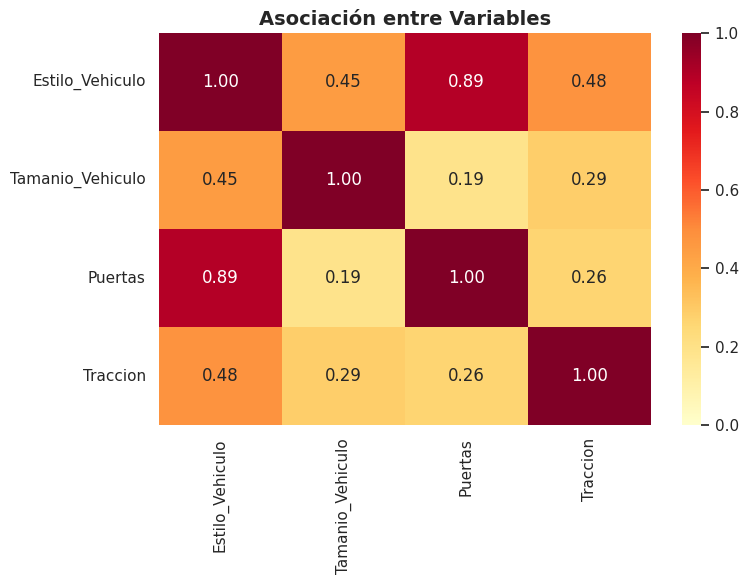

In [48]:
# ESTO SI SE QUIERE PARA MOSTRAR LA CORRELACION ENTRE ESTILO VEHICULO Y ESAS COSAS Q SE MENCIONAN ARRIBA COMO TAMAÑO, PUERTAS, TRACCION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# 1. Definimos una función para calcular el coeficiente de Cramér's V
def cramers_v(x, y):
    contingency_table = pd.crosstab(x, y)
    chi2 = chi2_contingency(contingency_table)[0]
    n = contingency_table.sum().sum()
    r, k = contingency_table.shape
    return np.sqrt(chi2 / (n * min(r - 1, k - 1)))

# 2. Seleccionamos las variables de interés para el análisis de colinealidad
variables_cat = ['Estilo_Vehiculo', 'Tamanio_Vehiculo', 'Puertas', 'Traccion']
df_cat_analisis = df_clean[variables_cat].copy()
# Tratamos puertas como categórica para este análisis
df_cat_analisis['Puertas'] = df_cat_analisis['Puertas'].astype(str)

# 3. Calculamos la matriz de asociación usando Cramér's V
matriz_asoc = pd.DataFrame(index=variables_cat, columns=variables_cat, dtype=float)
for col1 in variables_cat:
    for col2 in variables_cat:
        matriz_asoc.loc[col1, col2] = cramers_v(df_cat_analisis[col1], df_cat_analisis[col2])

# 4. Creamos la visualización únicamente del mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_asoc, annot=True, cmap='YlOrRd', vmin=0, vmax=1, fmt='.2f')
plt.title('Asociación entre Variables', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Se encontró una asociación muy fuerte entre Estilo_Vehiculo y Puertas (V = 0,89), y asociaciones moderadas con Tamanio_Vehiculo (V = 0,45) y Traccion (V = 0,48).

Estos resultados sugieren que Estilo_Vehiculo comparte parte de su información con variables ya incluidas en la regresión.

Por lo tanto, se refuerza la decisión de excluirla del modelo inicial, priorizando la simplicidad y evitando incorporar variables potencialmente redundantes.

---------------
### Prueba 1: incluir la variable `Marca`
En el modelo base no se incluyó `Marca` porque tiene 48 valores distintos, lo que genera 47 variables dummy. Acá se prueba qué pasa si se incluye igual.

In [49]:
# 1. Preparamos una nueva copia para incorporar la Marca
data_con_marca = df_clean.copy()
data_con_marca['Log_Precio'] = np.log(data_con_marca['Precio'])
data_con_marca['Rendimiento_Promedio_MPG'] = 0.55 * data_con_marca['Rendimiento_Ciudad_MPG'] + 0.45 * data_con_marca['Rendimiento_Ruta_MPG']

# 2. Definimos las variables incluyendo ahora a 'Marca'
var_numericas_m = ['Potencia_HP', 'Cilindros', 'Rendimiento_Promedio_MPG', 'Anio', 'Puertas']
var_categoricas_m = ['Marca', 'Tipo_Combustible', 'Tipo_Transmision', 'Traccion', 'Tamanio_Vehiculo']

# 3. Generamos las variables dummy incluyendo Marca (drop_first=True para evitar colinealidad)
dummies_con_marca = pd.get_dummies(data_con_marca[var_categoricas_m], drop_first=True, dtype=int)

# 4. Consolidamos predictores y target
X_m = pd.concat([data_con_marca[var_numericas_m], dummies_con_marca], axis=1)
y_m = data_con_marca['Log_Precio']

# Agregamos la constante
X_m_const = sm.add_constant(X_m)

# 5. Ajustamos el modelo OLS
modelo_con_marca_ols = sm.OLS(y_m, X_m_const).fit()

# 6. Imprimimos un resumen comparativo simplificado
print("=== COMPARACIÓN DE MODELOS (POBLACIÓN COMPLETA) ===\n")
print(f"Modelo anterior (Sin Marca):\n - R-squared ajustado: 0.713\n - Cantidad de Predictores: {X_completo.shape[1]}\n")
print(f"Modelo Nuevo (Con Marca):\n - R-squared ajustado: {modelo_con_marca_ols.rsquared_adj:.3f}\n - Cantidad de Predictores: {X_m.shape[1]}\n")


=== COMPARACIÓN DE MODELOS (POBLACIÓN COMPLETA) ===

Modelo anterior (Sin Marca):
 - R-squared ajustado: 0.713
 - Cantidad de Predictores: 18

Modelo Nuevo (Con Marca):
 - R-squared ajustado: 0.775
 - Cantidad de Predictores: 66



### Análisis: el impacto de incluir `Marca` (base completa)

#### 1. Capacidad explicativa ($R^2$ ajustado)
* **Sin marca:** el modelo explica el **71,3 %** de la variabilidad del precio, con 19 predictores.
* **Con marca:** explica el **77,5 %**, con 66 predictores.
* **Interpretación:** la marca suma **6,2 puntos porcentuales** de variabilidad explicada. El prestigio y el posicionamiento de cada marca influyen en el precio más allá de las características mecánicas.

#### 2. El costo: precisión vs. parsimonia
* **Complejidad:** para ganar esos 6,2 puntos hay que agregar **47 variables dummy** (de 19 a 66 predictores).
* Incorporar 47 variables dummy adicionales aumenta considerablemente la complejidad del modelo y podría incrementar el **riesgo de sobreajuste**, especialmente al trabajar con muestras pequeñas y marcas con pocas observaciones.

#### 3. Decisión
Se busca un punto medio: conservar la información de la marca sin agregar 47 dummies. Para eso, en la Prueba 3 se agrupan las marcas en **4 gamas**.

----------------------------------------
### Prueba 2: incluir `Estilo_Vehiculo`

In [50]:
# 1. Creamos una copia de trabajo de la base completa limpia
data_con_estilo = df_clean.copy()

# 2. Aplicamos la transformación logarítmica al target y combinamos rendimientos
data_con_estilo['Log_Precio'] = np.log(data_con_estilo['Precio'])
data_con_estilo['Rendimiento_Promedio_MPG'] = 0.55 * data_con_estilo['Rendimiento_Ciudad_MPG'] + 0.45 * data_con_estilo['Rendimiento_Ruta_MPG']

# 3. Definimos variables numéricas y categóricas (incluyendo 'Estilo_Vehiculo')
var_numericas_e = ['Potencia_HP', 'Cilindros', 'Rendimiento_Promedio_MPG', 'Anio', 'Puertas']
var_categoricas_e = ['Estilo_Vehiculo', 'Tipo_Combustible', 'Tipo_Transmision', 'Traccion', 'Tamanio_Vehiculo']

# 4. Generamos variables dummy (con drop_first=True para evitar colinealidad)
dummies_con_estilo = pd.get_dummies(data_con_estilo[var_categoricas_e], drop_first=True, dtype=int)

# 5. Consolidamos predictores (X) y target (y)
X_e = pd.concat([data_con_estilo[var_numericas_e], dummies_con_estilo], axis=1)
y_e = data_con_estilo['Log_Precio']

# Agregamos la constante requerida por statsmodels
X_e_const = sm.add_constant(X_e)

# 6. Ajustamos el modelo OLS
modelo_con_estilo_ols = sm.OLS(y_e, X_e_const).fit()

# 7. Imprimimos el resumen de comparación de performance
print("=== COMPARACIÓN DE MODELOS (POBLACIÓN COMPLETA) ===\n")
print(f"Modelo Base (Sin Estilo ni Marca):\n - R-squared ajustado: 0.713\n - Cantidad de Predictores: {X_completo.shape[1]}\n")
print(f"Modelo Nuevo (Con Estilo_Vehiculo):\n - R-squared ajustado: {modelo_con_estilo_ols.rsquared_adj:.3f}\n - Cantidad de Predictores: {X_e.shape[1]}\n")

# 8. Mostramos el resumen estadístico del nuevo modelo
print(modelo_con_estilo_ols.summary())

=== COMPARACIÓN DE MODELOS (POBLACIÓN COMPLETA) ===

Modelo Base (Sin Estilo ni Marca):
 - R-squared ajustado: 0.713
 - Cantidad de Predictores: 18

Modelo Nuevo (Con Estilo_Vehiculo):
 - R-squared ajustado: 0.733
 - Cantidad de Predictores: 34

                            OLS Regression Results                            
Dep. Variable:             Log_Precio   R-squared:                       0.734
Model:                            OLS   Adj. R-squared:                  0.733
Method:                 Least Squares   F-statistic:                     844.3
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:37:05   Log-Likelihood:                -6067.5
No. Observations:               10447   AIC:                         1.220e+04
Df Residuals:                   10412   BIC:                         1.246e+04
Df Model:                          34                                         
Covariance Type:            nonrobust      

**Análisis:** agregar el estilo sube el $R^2$ ajustado de **0,713 a 0,733** (solo 2 puntos porcentuales), a costa de **15 variables dummy** más (de 19 a 34 predictores).
La incorporación de Estilo_Vehiculo modificó considerablemente el coeficiente de Puertas, lo que sugiere que ambas variables comparten información relevante. Este resultado es coherente con la fuerte asociación observada previamente (0,89).

**Decisión:** no se incluye `Estilo_Vehiculo` en el modelo. La mejora es chica para la complejidad que agrega, y su información ya está en parte en `Puertas`, `Tamanio_Vehiculo` y `Traccion`. El estilo se usa, en cambio, para estratificar la muestra.

--------------
### Prueba 3 (modelo elegido): `Marca` agrupada en 4 gamas
Las 48 marcas se agrupan en 4 gamas según su **posicionamiento de mercado**: Gama alta / exóticos, Premium / lujo, Generalistas y Económicos / otros. Así se conserva la información de la marca con solo 3 variables dummy (la categoría de referencia es **Económicos / otros**). En la celda que sigue al análisis se valida la agrupación con los precios.

In [51]:
# 1. Definimos las listas de marcas de cada gama (criterio: posicionamiento de mercado de cada marca;
#    se valida con los precios en la celda siguiente)
gama_alta_exoticos = ['Bugatti', 'Spyker', 'McLaren', 'Ferrari', 'Lamborghini', 'Rolls-Royce', 'Bentley', 'Maybach', 'Aston Martin', 'Maserati', 'Tesla', 'Lotus']
premium_lujo = ['Mercedes-Benz', 'BMW', 'Audi', 'Lexus', 'Infiniti', 'Acura', 'Land Rover', 'Porsche', 'Lincoln', 'Cadillac', 'Volvo', 'Genesis', 'Alfa Romeo']
generalistas_medios = ['Toyota', 'Volkswagen', 'Nissan', 'Honda', 'Mazda', 'Ford', 'Chevrolet', 'GMC', 'Dodge', 'Subaru', 'Hyundai', 'Kia', 'Buick', 'Chrysler']
economicos_otros = ['Suzuki', 'Mitsubishi', 'Pontiac', 'Saab', 'Oldsmobile', 'FIAT', 'Scion', 'HUMMER', 'Plymouth']

def asignar_gama(marca):
    if marca in gama_alta_exoticos:
        return 'Gama Alta_Exoticos'
    elif marca in premium_lujo:
        return 'Premium_Lujo'
    elif marca in generalistas_medios:
        return 'Generalistas_Medios'
    else:
        return 'Economicos_Otros'

# 2. Copiamos la base de datos limpia
data_gamas = df_clean.copy()
data_gamas['Gama_Marca'] = data_gamas['Marca'].apply(asignar_gama)

# 3. Aplicamos la transformación logarítmica y rendimiento promedio
data_gamas['Log_Precio'] = np.log(data_gamas['Precio'])
data_gamas['Rendimiento_Promedio_MPG'] = 0.55 * data_gamas['Rendimiento_Ciudad_MPG'] + 0.45 * data_gamas['Rendimiento_Ruta_MPG']

# 4. Definimos variables numéricas y categóricas (incluyendo 'Gama_Marca' y excluyendo 'Estilo_Vehiculo')
var_numericas_g = ['Potencia_HP', 'Cilindros', 'Rendimiento_Promedio_MPG', 'Anio', 'Puertas']
var_categoricas_g = ['Gama_Marca', 'Tipo_Combustible', 'Tipo_Transmision', 'Traccion', 'Tamanio_Vehiculo']

# 5. Generamos las variables dummy con drop_first=True

dummies_gamas = pd.get_dummies(data_gamas[var_categoricas_g], drop_first=True, dtype=int)

# 6. Consolidamos predictores (X) y target (y)
X_g = pd.concat([data_gamas[var_numericas_g], dummies_gamas], axis=1)
y_g = data_gamas['Log_Precio']

# Agregamos la constante
X_g_const = sm.add_constant(X_g)

# 7. Ajustamos el modelo OLS
modelo_gamas_ols = sm.OLS(y_g, X_g_const).fit()

# 8. Reporte comparativo de métricas
print("=== COMPARACIÓN DE MODELOS (POBLACIÓN COMPLETA) ===\n")
print(f"Modelo Base (Sin Marcas ni Gamas):\n - R-squared ajustado: 0.713\n - Cantidad de Predictores: 19\n")
print(f"Modelo Nuevo (Con Agrupación por Gamas de Marca):\n - R-squared ajustado: {modelo_gamas_ols.rsquared_adj:.3f}\n - Cantidad de Predictores: {X_g.shape[1]}\n")

# 9. Mostramos el resumen completo del nuevo modelo
print(modelo_gamas_ols.summary())

=== COMPARACIÓN DE MODELOS (POBLACIÓN COMPLETA) ===

Modelo Base (Sin Marcas ni Gamas):
 - R-squared ajustado: 0.713
 - Cantidad de Predictores: 19

Modelo Nuevo (Con Agrupación por Gamas de Marca):
 - R-squared ajustado: 0.756
 - Cantidad de Predictores: 22

                            OLS Regression Results                            
Dep. Variable:             Log_Precio   R-squared:                       0.756
Model:                            OLS   Adj. R-squared:                  0.756
Method:                 Least Squares   F-statistic:                     1468.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:37:05   Log-Likelihood:                -5612.9
No. Observations:               10447   AIC:                         1.127e+04
Df Residuals:                   10424   BIC:                         1.144e+04
Df Model:                          22                                         
Covariance Type:            n

**Análisis del modelo con gamas (base completa):**
- El $R^2$ ajustado sube de **0,713 a 0,756** agregando **solo 3 predictores**. Es más de dos tercios de la mejora que lograba la marca completa (0,775) con 44 dummies menos. Por eso es el **modelo clásico elegido**.
- **Gama alta / exóticos:** coeficiente 0,919 → $(e^{0,919} - 1) \times 100 \approx$ **+151 %**. A igual potencia, año y demás características, un auto de una marca exótica cuesta en promedio 2,5 veces más que uno de la gama de referencia.
- **Generalistas:** −0,163 → **−15 %** respecto de "Económicos / otros". **Premium:** no es significativa (p = 0,456). Estos dos resultados sorprenden, y se explican porque la comparación es *a igual potencia, año y equipamiento*: la potencia y el año ya capturan gran parte de la diferencia de precio, y "Económicos / otros" es un grupo heterogéneo (incluye marcas discontinuadas como Saab, HUMMER u Oldsmobile).
- **Otros efectos:** cada año más nuevo, **+7,0 %**; cada HP adicional, **+0,24 %**; la transmisión manual, **−20,1 %** respecto de la automática.
- Al incorporar las gamas de marca, el coeficiente de Cilindros disminuyó de 0,0998 a 0,0539. Esto sugiere que parte de la asociación inicialmente atribuida a la cantidad de cilindros estaba relacionada con el posicionamiento comercial de la marca. El resultado evidencia cómo la incorporación de nuevas variables explicativas puede modificar la interpretación de los coeficientes del modelo

**Por estos motivos, se seleccionó el modelo con marcas agrupadas en gamas como modelo estadístico clásico principal, priorizando un equilibrio entre capacidad explicativa, interpretabilidad y parsimonia.**

In [52]:
# Validación de las gamas con los datos: precio mediano de cada gama y de cada marca
resumen_gamas = data_gamas.groupby("Gama_Marca")["Precio"].agg(["count", "median", "mean"]).sort_values("median")
resumen_gamas.columns = ["Cantidad de autos", "Precio mediano", "Precio promedio"]
display(resumen_gamas.round(0))

por_marca = (data_gamas.groupby(["Gama_Marca", "Marca"])["Precio"].median()
             .rename("Precio mediano").reset_index().sort_values("Precio mediano"))
display(por_marca.reset_index(drop=True))

,Cantidad de autos,Precio mediano,Precio promedio
Gama_Marca,,,
Economicos_Otros,963,22695.0,22782.0
Generalistas_Medios,6311,28250.0,29248.0
Premium_Lujo,2729,47515.0,56855.0
Gama Alta_Exoticos,444,212800.0,239247.0


,Gama_Marca,Marca,Precio mediano
0,Economicos_Otros,Plymouth,2234.0
1,Economicos_Otros,Suzuki,18249.0
2,Economicos_Otros,Scion,19205.0
3,Economicos_Otros,Oldsmobile,22455.0
4,Economicos_Otros,FIAT,22535.0
5,Generalistas_Medios,Mazda,23210.0
6,Generalistas_Medios,Hyundai,23999.0
7,Economicos_Otros,Mitsubishi,23999.0
8,Economicos_Otros,Pontiac,24220.0
9,Generalistas_Medios,Kia,24340.0


**Validación de las gamas:** la agrupación se hizo por posicionamiento de mercado y no por precio, para no usar la variable objetivo para construir un predictor. La tabla confirma que es coherente con los datos: el precio mediano sube de gama en gama (Económicos USD 22.695 → Generalistas 28.250 → Premium 47.515 → Exóticos 212.800).

En la tabla por marca hay pocos casos de borde. Por ejemplo, HUMMER y Saab tienen precios medianos de nivel premium bajo pero quedaron en "Económicos / otros", y Porsche es premium con precios de exótico. Genesis y Alfa Romeo, que en la primera versión estaban en "Económicos / otros", se pasaron a Premium porque sus precios y su posicionamiento corresponden a esa gama.

### Regresión Lineal Múltiple con Agrupación por Gamas en la Muestra ($n=750$)

Procedemos a ajustar el modelo utilizando la variable sintética `Gama_Marca` sobre las observaciones de nuestra muestra representativa.

In [53]:
# 1. Copiamos la muestra de 750 observaciones para el análisis
muestra_gamas = muestra_750.copy()

# 2. Aplicamos la misma función de asignación de gama
muestra_gamas['Gama_Marca'] = muestra_gamas['Marca'].apply(asignar_gama)

# 3. Aplicamos la transformación logarítmica y rendimiento promedio ponderado
muestra_gamas['Log_Precio'] = np.log(muestra_gamas['Precio'])
muestra_gamas['Rendimiento_Promedio_MPG'] = 0.55 * muestra_gamas['Rendimiento_Ciudad_MPG'] + 0.45 * muestra_gamas['Rendimiento_Ruta_MPG']

# 4. Variables explicativas
var_numericas_mg = ['Potencia_HP', 'Cilindros', 'Rendimiento_Promedio_MPG', 'Anio', 'Puertas']
var_categoricas_mg = ['Gama_Marca', 'Tipo_Combustible', 'Tipo_Transmision', 'Traccion', 'Tamanio_Vehiculo']

# 5. Generamos variables dummy (drop_first=True para evitar la trampa de colinealidad)
dummies_muestra_gamas = pd.get_dummies(muestra_gamas[var_categoricas_mg], drop_first=True, dtype=int)

# 5b. Igual que en el primer modelo de la muestra: transmisión directa y eléctrico son columnas idénticas
if "Tipo_Transmision_TRANSMISION_DIRECTA" in dummies_muestra_gamas and (dummies_muestra_gamas["Tipo_Transmision_TRANSMISION_DIRECTA"] == dummies_muestra_gamas["Tipo_Combustible_electrico"]).all():
    dummies_muestra_gamas = dummies_muestra_gamas.drop(columns="Tipo_Transmision_TRANSMISION_DIRECTA")

# 6. Consolidamos predictores (X) y target (y)
X_mg_m = pd.concat([muestra_gamas[var_numericas_mg], dummies_muestra_gamas], axis=1)
y_mg_m = muestra_gamas['Log_Precio']

# Agregamos la constante
X_mg_m_const = sm.add_constant(X_mg_m)

# 7. Ajustamos el modelo OLS sobre la muestra de 750 observaciones
modelo_muestra_gamas_ols = sm.OLS(y_mg_m, X_mg_m_const).fit()

# 8. Reporte comparativo simplificado
print("=== COMPARACIÓN DE MODELOS CON GAMAS ===\n")
print(f"Modelo Poblacional Completo (N = 10.447):\n - R-squared ajustado: {modelo_gamas_ols.rsquared_adj:.3f}\n - Cantidad de Predictores: {X_g.shape[1]}\n")
print(f"Modelo sobre la Muestra (n = 750):\n - R-squared ajustado: {modelo_muestra_gamas_ols.rsquared_adj:.3f}\n - Cantidad de Predictores: {X_mg_m.shape[1]}\n")

# 9. Resumen completo del modelo sobre la muestra
print(modelo_muestra_gamas_ols.summary())

=== COMPARACIÓN DE MODELOS CON GAMAS ===

Modelo Poblacional Completo (N = 10.447):
 - R-squared ajustado: 0.756
 - Cantidad de Predictores: 22

Modelo sobre la Muestra (n = 750):
 - R-squared ajustado: 0.754
 - Cantidad de Predictores: 20

                            OLS Regression Results                            
Dep. Variable:             Log_Precio   R-squared:                       0.760
Model:                            OLS   Adj. R-squared:                  0.754
Method:                 Least Squares   F-statistic:                     115.7
Date:                Mon, 16 Nov 2026   Prob (F-statistic):          2.16e-210
Time:                        02:37:06   Log-Likelihood:                -381.37
No. Observations:                 750   AIC:                             804.7
Df Residuals:                     729   BIC:                             901.8
Df Model:                          20                                         
Covariance Type:            nonrobust           

**Análisis: el modelo con gamas en la muestra (n = 750) vs. la base completa:**
- El $R^2$ ajustado es prácticamente el mismo: **0,754** en la muestra contra **0,756** en la base completa.
- Los coeficientes principales se mantienen: año (+6,8 % contra +7,0 %), potencia (0,19 % contra 0,24 % por HP) y transmisión manual (−19,5 % contra −20,1 %). La gama exótica da +183 % en la muestra contra +151 % en la base completa. Es la diferencia más grande, porque en la muestra hay muy pocos autos exóticos.
- Los **errores estándar son unas 3,7 veces más grandes** en la muestra (por ejemplo, 0,110 contra 0,029 en la gama exótica). Por eso varias variables que son significativas en la base completa dejan de serlo en la muestra: las tres de tracción, las dos de tamaño, nafta premium y transmisión manual automatizada.
- **Conclusión:**  Con menos observaciones, el modelo presenta menor precisión para estimar los coeficientes, por lo que algunos efectos que son significativos en la base completa dejan de serlo en la muestra

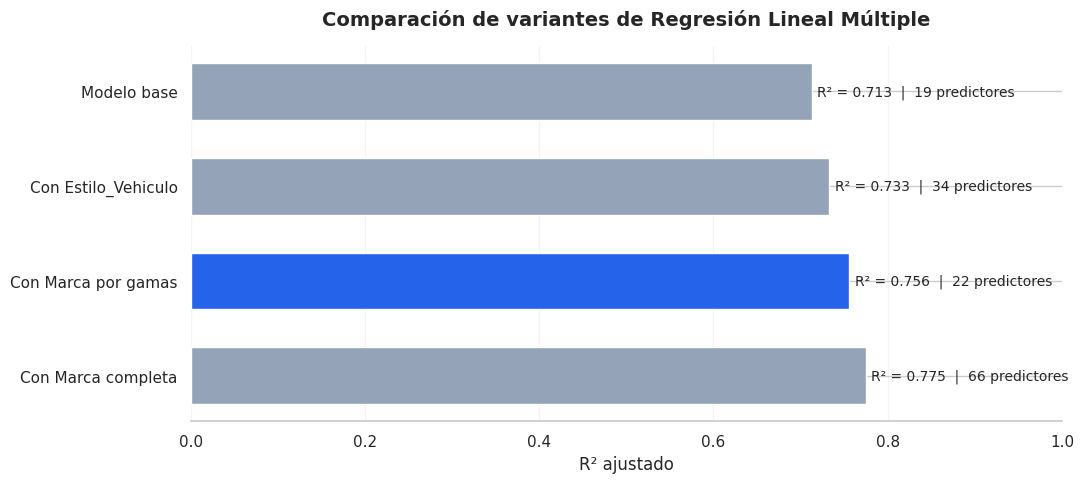

In [54]:

import matplotlib.pyplot as plt
import numpy as np

# Resultados de los experimentos
modelos = [
    "Modelo base",
    "Con Estilo_Vehiculo",
    "Con Marca por gamas",
    "Con Marca completa"
]

r2_ajustado = [0.713, 0.733, 0.756, 0.775]
predictores = [19, 34, 22, 66]

colores = ["#94A3B8", "#94A3B8", "#2563EB", "#94A3B8"]

fig, ax = plt.subplots(figsize=(11, 5))

barras = ax.barh(modelos, r2_ajustado, color=colores, height=0.6)

for i, (r2, n) in enumerate(zip(r2_ajustado, predictores)):
    ax.text(
        r2 + 0.006, i,
        f"R² = {r2:.3f}  |  {n} predictores",
        va="center", fontsize=10
    )

ax.set_xlim(0, 1)
ax.set_xlabel("R² ajustado")
ax.set_title(
    "Comparación de variantes de Regresión Lineal Múltiple",
    fontsize=14, fontweight="bold", pad=15
)

ax.invert_yaxis()
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Luego de evaluar las distintas variantes, se decidió seleccionar el modelo con marcas agrupadas en cuatro gamas, ya que ofrece un buen equilibrio entre capacidad explicativa, simplicidad e interpretabilidad.

Este modelo alcanzó un R² ajustado de 0,756 con solo 22 predictores, logrando una mejora considerable respecto del modelo inicial (0,713), sin necesidad de incorporar las 47 variables dummy adicionales del modelo con marcas individuales.

Además, al aplicarlo sobre la muestra de 750 observaciones, se obtuvo un R² ajustado de 0,754, muy similar al de la base completa (N = 10.447). Los principales coeficientes conservaron signos y magnitudes relativamente estables, aunque con mayores errores estándar en la muestra.

**En conclusión, se eligió este modelo por su capacidad para explicar aproximadamente el 75,6% de la variabilidad del logaritmo del precio, manteniendo una estructura relativamente sencilla. La comparación entre muestra y población también permitió evidenciar cómo un mayor tamaño muestral mejora la precisión de las estimaciones, sin producir necesariamente grandes cambios en la bondad de ajuste.**

---
# iv) Machine Learning y Validación (Unidad 6)

En esta sección se trabaja sobre la **base total** ($N = 10.447$). El objetivo deja de ser interpretar coeficientes y pasa a ser **predecir el precio de autos que el modelo nunca vio**.

Decisiones de diseño:
* **Mismas variables que el modelo clásico final** (el modelo con `Gama_Marca`), para que la comparación entre Estadística y Machine Learning sea justa: misma información, distinto algoritmo.
* **Target:** `Log_Precio`, igual que en la regresión lineal. Las métricas de error se informan **en dólares** (volviendo de logaritmo a precio con `np.exp`), porque es la unidad que entiende un usuario del negocio. El $R^2$ se informa sobre `Log_Precio`.
* **División Train/Test 80/20** con semilla fija (`random_state=42`) para que el resultado sea reproducible.

In [55]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reutilizamos la matriz de predictores del modelo clásico final (con Gama_Marca) sobre la base total
X_ml = X_g.copy()
y_ml = y_g.copy()          # Log_Precio

X_train, X_test, y_train, y_test = train_test_split(X_ml, y_ml, test_size=0.20, random_state=42)

print(f"Train: {X_train.shape[0]} observaciones | Test: {X_test.shape[0]} observaciones")
print(f"Cantidad de predictores: {X_train.shape[1]}")

Train: 8357 observaciones | Test: 2090 observaciones
Cantidad de predictores: 22


In [56]:
# Predictores que usan todos los modelos de esta sección (los mismos del modelo clásico con gamas)
print(f"Total de predictores: {X_train.shape[1]}\n")
for col in X_train.columns:
    print(" -", col)

Total de predictores: 22

 - Potencia_HP
 - Cilindros
 - Rendimiento_Promedio_MPG
 - Anio
 - Puertas
 - Gama_Marca_Gama Alta_Exoticos
 - Gama_Marca_Generalistas_Medios
 - Gama_Marca_Premium_Lujo
 - Tipo_Combustible_electrico
 - Tipo_Combustible_flex-fuel
 - Tipo_Combustible_gas natural
 - Tipo_Combustible_nafta comun
 - Tipo_Combustible_nafta premium
 - Tipo_Transmision_DESCONOCIDA
 - Tipo_Transmision_MANUAL
 - Tipo_Transmision_MANUAL_AUTOMATIZADA
 - Tipo_Transmision_TRANSMISION_DIRECTA
 - Traccion_traccion delantera
 - Traccion_traccion integral (AWD)
 - Traccion_traccion trasera
 - Tamanio_Vehiculo_Grande
 - Tamanio_Vehiculo_Mediano


**Predictores:** son los **22 predictores** del modelo clásico con gamas:
- **5 numéricos:** potencia, cilindros, rendimiento promedio, año y puertas.
- **3 dummies de gama de marca** (referencia: Económicos / otros).
- **5 dummies de combustible** (referencia: diésel).
- **4 dummies de transmisión** (referencia: automática).
- **3 dummies de tracción** (referencia: 4x4).
- **2 dummies de tamaño** (referencia: compacto).

Se usan los mismos predictores en todos los modelos para que la comparación sea justa: misma información, distinto algoritmo.

**¿Por qué dividimos en Train y Test?** El modelo aprende únicamente con el 80% de los datos (Train). El 20% restante (Test) queda guardado y recién se usa al final, como un "examen sorpresa" con autos que el modelo nunca vio. Si evaluáramos con los mismos datos de entrenamiento, el resultado sería engañosamente bueno: un modelo que memoriza obtendría una nota perfecta sin saber generalizar.

In [57]:
def metricas(modelo, X, y_log):
    # Calcula MAE, MSE y RMSE en dólares y R² sobre Log_Precio
    pred_log = modelo.predict(X)
    real = np.exp(y_log)
    pred = np.exp(pred_log)
    mse = mean_squared_error(real, pred)
    return {
        "MAE (USD)": mean_absolute_error(real, pred),
        "MSE": mse,
        "RMSE (USD)": np.sqrt(mse),
        "R² (log)": r2_score(y_log, pred_log),
    }

def evaluar(nombre, modelo):
    filas = []
    for conjunto, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        m = metricas(modelo, X, y)
        m["Modelo"], m["Conjunto"] = nombre, conjunto
        filas.append(m)
    return pd.DataFrame(filas).set_index(["Modelo", "Conjunto"])

resultados = []

**Métricas de evaluación (qué significa cada columna de las tablas):**
- **MAE (error absoluto medio, en USD):** en promedio, por cuántos dólares se equivoca el modelo al predecir el precio de un auto. Es la métrica más fácil de explicar y no se deja influir tanto por casos extremos.
- **MSE (error cuadrático medio):** el promedio de los errores elevados al cuadrado. Castiga mucho los errores grandes, y su unidad (dólares al cuadrado) no tiene interpretación directa; por eso se acompaña con el RMSE.
- **RMSE (raíz del MSE, en USD):** vuelve a dólares. Como eleva los errores al cuadrado, unos pocos errores grandes (por ejemplo, en un superdeportivo) lo inflan mucho. Si el RMSE es mucho mayor que el MAE, hay pocos errores muy grandes.
- **R² (sobre log del precio):** qué proporción de la variabilidad del precio explica el modelo, comparado con predecir siempre el promedio. Va de 0 a 1 (más alto es mejor).

Para detectar **sobreajuste** se compara cada métrica en **Train** (datos que el modelo vio) y en **Test** (datos nuevos).

### 1. Línea de base: Regresión Lineal (modelo clásico) evaluada como predictor

Antes de los algoritmos de Machine Learning, se entrena la **misma regresión lineal** del punto iii) pero solo con Train, y se evalúa en Test. Así se mide la capacidad predictiva del modelo estadístico con las mismas reglas que los modelos de ML.

In [58]:
lineal = LinearRegression().fit(X_train, y_train)
res_lineal = evaluar("Regresión Lineal", lineal)
resultados.append(res_lineal)
res_lineal.round(3)

MAE (USD)           MSE  RMSE (USD)  R² (log)
Modelo           Conjunto                                               
Regresión Lineal Train     11810.804  1.294045e+09   35972.839     0.759
                 Test      11915.807  6.879398e+08   26228.607     0.743

**Análisis:** la regresión lineal obtiene un $R^2$ de 0,759 en Train y 0,743 en Test. La diferencia es muy chica, no presenta señales importantes de sobreajuste según la comparación del R². Con autos que no vio, se equivoca en promedio unos **USD 11.900** (MAE).

El RMSE es mayor en Train (USD 35.973) que en Test (USD 26.229). No es un error: el RMSE eleva los errores al cuadrado, y en Train quedaron algunos superdeportivos de más de un millón de dólares en los que el modelo se equivoca por mucho. Por eso, para comparar Train y Test se miran principalmente el $R^2$ y el MAE.

### 2. Árbol de Decisión sin restricciones (para mostrar el sobreajuste)

In [59]:
arbol_libre = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
res_arbol_libre = evaluar("Árbol sin límite", arbol_libre)
resultados.append(res_arbol_libre)
print("Profundidad alcanzada:", arbol_libre.get_depth(), "| Hojas:", arbol_libre.get_n_leaves())
res_arbol_libre.round(3)

Profundidad alcanzada: 29 | Hojas: 4345


MAE (USD)           MSE  RMSE (USD)  R² (log)
Modelo           Conjunto                                               
Árbol sin límite Train      2093.400  1.526194e+08   12353.921     0.993
                 Test       4454.183  2.184941e+08   14781.546     0.970

**Análisis:** el árbol sin límite crece hasta **29 niveles y 4.345 hojas**: casi una regla cada 2 autos. En Train es casi perfecto ($R^2$ = 0,993, MAE ≈ USD 2.100), pero en Test el error **se duplica** (MAE ≈ USD 4.280) y el $R^2$ baja a 0,972.

**¿Por qué decimos que sobreajusta si en Test el $R^2$ sigue siendo muy alto (0,970)?**

1. **Lo que importa es la brecha, no el número.** El sobreajuste se mide comparando Train con Test. En Train el árbol se equivoca en unos USD 2.100 y en Test en unos USD 4.454: **el error se duplica** con datos nuevos. Es la brecha más grande de todos los modelos (0,023 en $R^2$).
2. **La estructura lo delata.** Un árbol con 4.345 hojas para 8.357 autos tiene casi una regla para cada 2 autos: memorizó casos puntuales en lugar de aprender reglas generales.
3. **El $R^2$ en Test está "inflado".** Como hay versiones casi idénticas del mismo auto, muchas veces el árbol encuentra en Train una versión gemela del auto de Test y "acierta" sin haber aprendido nada general. Mas adelante hicimos otra variante, donde ningún modelo de auto aparece en Train y en Test a la vez, el mismo árbol pasa de un $R^2$ de 0,993 en Train a **0,871** en Test, y su MAE sube de USD 2.250 a **USD 13.700**. Ahí el sobreajuste se ve con claridad.

### 3. Árbol de Decisión con hiperparámetros controlados

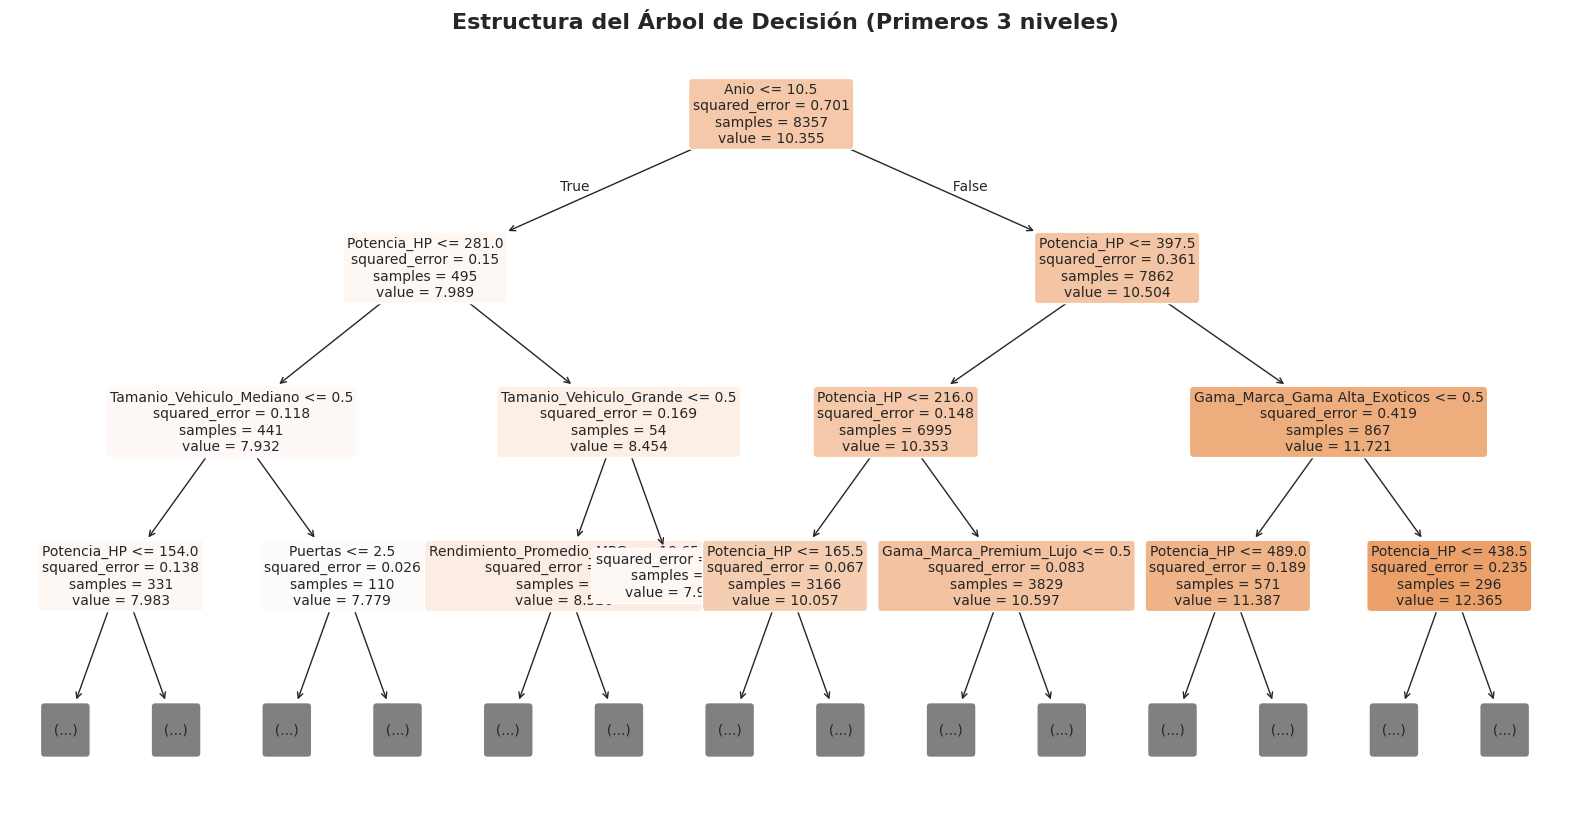

MAE (USD)           MSE  RMSE (USD)  R² (log)
Modelo               Conjunto                                               
Árbol (max_depth=10) Train      5135.151  5.937606e+08   24367.204     0.973
                     Test       5130.787  1.348175e+08   11611.093     0.965

In [60]:
from sklearn.tree import plot_tree

arbol = DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=42).fit(X_train, y_train)
res_arbol = evaluar("Árbol (max_depth=10)", arbol)
resultados.append(res_arbol)

# Visualización gráfica del árbol (primeros niveles para mayor legibilidad)
plt.figure(figsize=(20, 10))
plot_tree(
    arbol,
    max_depth=3,
    feature_names=X_train.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Estructura del Árbol de Decisión (Primeros 3 niveles)", fontsize=16, fontweight='bold')
plt.show()

res_arbol.round(3)

**Análisis:** al limitar la profundidad a 10 y exigir al menos 5 autos por hoja, el árbol deja de memorizar: el $R^2$ pasa de 0,973 en Train a 0,965 en Test, y el MAE es casi igual en los dos (USD 5.135 y 5.131). La brecha baja a 0,008, menos de la mitad que la del árbol sin límite. A cambio, el error típico en Test es algo mayor (MAE ≈ USD 5.130 contra 4.280): es el costo de un modelo más simple, y un buen ejemplo del equilibrio entre sobreajuste y capacidad predictiva.

- **Menor sobreajuste:** la diferencia entre R² de Train y Test disminuye de 0,023 a 0,008.

- **Mayor simplicidad:** el árbol tiene restricciones que impiden generar divisiones excesivamente específicas.

- **MAE Test ligeramente peor:** aumenta de USD 4.454 a USD 5.131.

- **RMSE Test mejor:** disminuye de USD 14.782 a USD 11.611, lo que sugiere que el árbol restringido comete menos errores extremadamente grandes.

Esto evidencia el equilibrio entre complejidad del modelo, capacidad de ajuste y generalización.

### 4. Random Forest
Se entrenó un modelo Random Forest compuesto por 300 árboles de decisión, utilizando la técnica de Bagging para combinar sus predicciones y reducir la variabilidad asociada a un árbol individual.



In [61]:
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)
res_rf = evaluar("Random Forest", rf)
resultados.append(res_rf)
res_rf.round(3)

MAE (USD)           MSE  RMSE (USD)  R² (log)
Modelo        Conjunto                                               
Random Forest Train      2729.633  2.092390e+08   14465.096     0.992
              Test       4050.000  1.257347e+08   11213.148     0.978

**Análisis**

El modelo obtuvo un R² de 0,978 en Test, un MAE de aproximadamente USD 4.050 y un RMSE de USD 11.213, superando a los árboles de decisión anteriores en las tres métricas.

La diferencia entre el R² de entrenamiento (0,992) y prueba (0,978) fue relativamente pequeña, lo que indica una buena capacidad de generalización sobre el conjunto de prueba utilizado, aunque se observa cierto sobreajuste.

Estos resultados muestran que combinar múltiples árboles permite mejorar la estabilidad y precisión de las predicciones frente a utilizar un único árbol de decisión.

### 5. Gradient Boosting
Se entrenó un modelo Gradient Boosting utilizando sus hiperparámetros por defecto (100 árboles de profundidad máxima 3).

In [62]:
gb = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)
res_gb = evaluar("Gradient Boosting", gb)
resultados.append(res_gb)
res_gb.round(3)

MAE (USD)           MSE  RMSE (USD)  R² (log)
Modelo            Conjunto                                               
Gradient Boosting Train      6564.633  5.446033e+08   23336.737     0.961
                  Test       6575.754  2.108936e+08   14522.175     0.954

El modelo obtuvo un R² de 0,954 en Test, un MAE de aproximadamente USD 6.576 y un RMSE de USD 14.522, mostrando un rendimiento inferior al de Random Forest.

La diferencia entre el R² de entrenamiento (0,961) y prueba (0,954) fue pequeña, por lo que no se observaron señales importantes de sobreajuste según esta métrica.

Sin embargo, el rendimiento inferior respecto de Random Forest sugiere que la configuración inicial de Gradient Boosting podría mejorarse mediante un ajuste de hiperparámetros.

lo usaremos en optimizacion de parametros, evaluando si una configuración diferente permite reducir los errores y mejorar su capacidad predictiva.

### 6. Validación cruzada (K-Fold, k = 5)
Un único split Train/Test es "una sola foto". Con validación cruzada, el conjunto de entrenamiento se divide en 5 partes; cada parte funciona una vez como validación y se promedian los 5 errores. Se mira el **promedio** (qué tan bueno es) y el **desvío** (qué tan estable es).

In [63]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
modelos_cv = {
    "Regresión Lineal": LinearRegression(),
    "Árbol (max_depth=10)": DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
filas_cv = []
for nombre, m in modelos_cv.items():
    scores = cross_val_score(m, X_train, y_train, cv=kf, scoring="r2")
    filas_cv.append({"Modelo": nombre, "R² CV promedio": scores.mean(), "Desvío entre pliegues": scores.std()})
tabla_cv = pd.DataFrame(filas_cv).set_index("Modelo")
tabla_cv.round(4)

,R² CV promedio,Desvío entre pliegues
Modelo,,
Regresión Lineal,0.7556,0.0133
Árbol (max_depth=10),0.9608,0.0027
Random Forest,0.9764,0.0010
Gradient Boosting,0.9565,0.0041


**Análisis:** todos los modelos de árboles superan ampliamente a la regresión lineal ($R^2$ entre 0,957 y 0,976, contra 0,756). Random Forest tiene el mejor promedio (0,976) y además el **desvío entre pliegues más bajo** (0,001): su rendimiento casi no cambia según qué datos tocaron en cada pliegue, lo que indica un modelo muy estable. La regresión lineal es la que más varía entre pliegues (desvío 0,013).

### 7. Optimización de hiperparámetros (Random Search + validación cruzada)
Se optimiza el mejor modelo de ensamble. Se usa **Random Search** porque probar todas las combinaciones (Grid Search) sería muy costoso: prueba combinaciones al azar y evalúa cada una con validación cruzada de 5 pliegues, **solo con los datos de Train** (el Test no se toca). esto para encontrar una combinación de hiperparámetros que mejorara el rendimiento inicial de Gradient Boosting

In [64]:
param_dist = {
    "n_estimators": [200, 400, 600],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [3, 4, 5, 6],
    "min_samples_leaf": [1, 5, 10],
    "subsample": [0.8, 1.0],
}
busqueda = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=15, cv=kf, scoring="r2", random_state=42, n_jobs=-1,
)
busqueda.fit(X_train, y_train)
print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"R² promedio en CV con esa configuración: {busqueda.best_score_:.4f}")

gb_opt = busqueda.best_estimator_
res_gb_opt = evaluar("Gradient Boosting optimizado", gb_opt)
resultados.append(res_gb_opt)
res_gb_opt.round(3)

Mejores hiperparámetros: {'subsample': 1.0, 'n_estimators': 400, 'min_samples_leaf': 1, 'max_depth': 6, 'learning_rate': 0.1}
R² promedio en CV con esa configuración: 0.9787


MAE (USD)           MSE  RMSE (USD)  R² (log)
Modelo                       Conjunto                                               
Gradient Boosting optimizado Train      2803.254  1.596994e+08   12637.221     0.991
                             Test       3871.064  1.282005e+08   11322.565     0.981

**Análisis:**

La configuración seleccionada incorporó 400 árboles de profundidad máxima 6 y permitió aumentar el R² promedio de validación cruzada de aproximadamente 0,957 a 0,979.

En Test, el modelo optimizado alcanzó un R² de 0,981, un MAE de USD 3.871 y un RMSE de USD 11.323, superando a Random Forest en R² y MAE, aunque este último mantuvo un RMSE ligeramente menor.

La diferencia entre el R² de Train (0,991) y Test (0,981) fue reducida, sin evidenciar un sobreajuste importante según esta métrica.

--------
Dado que Random Forest obtuvo resultados muy competitivos sin optimización, se decidió realizar una búsqueda de hiperparámetros para evaluar si era posible mejorar su rendimiento.

In [65]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

param_rf = {
    "n_estimators": [200, 300, 400, 600],
    "max_depth": [None, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": [0.7, 1.0]
}

busqueda_rf = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions=param_rf,
    n_iter=15,
    cv=kf,
    scoring="r2",
    random_state=42,
    n_jobs=-1
)

busqueda_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_rf.best_params_)
print("R² promedio CV:", round(busqueda_rf.best_score_,3))

rf_opt = busqueda_rf.best_estimator_

res_rf_opt = evaluar("Random Forest optimizado", rf_opt)
resultados.append(res_rf_opt)

display(res_rf_opt.round(3))

Mejores hiperparámetros: {'n_estimators': 400, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 20}
R² promedio CV: 0.978


MAE (USD)           MSE  RMSE (USD)  R² (log)
Modelo                   Conjunto                                               
Random Forest optimizado Train      3010.439  2.571725e+08   16036.598     0.991
                         Test       3999.808  1.080020e+08   10392.403     0.978

 seleccionó una configuración de **400 árboles, profundidad máxima de 20, mínimo de 5 muestras para dividir un nodo, mínimo de 1 observación por hoja y utilización del 70% de las variables en cada división**.

Con esta configuración, se obtuvo un R² promedio de 0,9775 en validación cruzada.

En el conjunto Test, el modelo alcanzó:

- R² = 0,978, prácticamente igual al Random Forest original.

- MAE = USD 4.000, ligeramente inferior al modelo original (USD 4.050).

- RMSE = USD 10.392, mejorando respecto de los USD 11.213 del modelo original.

La diferencia entre el R² de Train (0,991) y Test (0,978) fue de 0,013, sin evidenciar un sobreajuste importante según esta métrica.

En conclusión, la optimización no produjo una mejora significativa en el R², pero sí permitió reducir los errores de predicción, especialmente el RMSE, lo que indica una mejora en el comportamiento frente a errores grandes.

### 8. Tabla comparativa final

In [66]:
tabla_final = pd.concat(resultados)
tabla_test = tabla_final.xs("Test", level="Conjunto").sort_values("RMSE (USD)")
print("=== Desempeño sobre TEST (datos no vistos) ===")
display(tabla_test.round(3))

# Brecha de sobreajuste: cuánto empeora el R² de Train a Test
brecha = (tabla_final.xs("Train", level="Conjunto")["R² (log)"] - tabla_final.xs("Test", level="Conjunto")["R² (log)"]).rename("Brecha R² (Train − Test)")
display(brecha.round(4).to_frame())

=== Desempeño sobre TEST (datos no vistos) ===


,MAE (USD),MSE,RMSE (USD),R² (log)
Modelo,,,,
Random Forest optimizado,3999.808,1.080020e+08,10392.403,0.978
Random Forest,4050.000,1.257347e+08,11213.148,0.978
Gradient Boosting optimizado,3871.064,1.282005e+08,11322.565,0.981
Árbol (max_depth=10),5130.787,1.348175e+08,11611.093,0.965
Gradient Boosting,6575.754,2.108936e+08,14522.175,0.954
Árbol sin límite,4454.183,2.184941e+08,14781.546,0.970
Regresión Lineal,11915.807,6.879398e+08,26228.607,0.743


,Brecha R² (Train − Test)
Modelo,
Regresión Lineal,0.0157
Árbol sin límite,0.0229
Árbol (max_depth=10),0.0078
Random Forest,0.0139
Gradient Boosting,0.0066
Gradient Boosting optimizado,0.0099
Random Forest optimizado,0.0126


### Análisis comparativo final

Los modelos de Machine Learning superaron ampliamente a la regresión lineal en capacidad predictiva sobre Test.

**Gradient Boosting optimizado** obtuvo el mayor R² (0,981) y el menor MAE (USD 3.871), reduciendo el error promedio un **67,5% respecto de la regresión lineal**. Por su parte, **Random Forest optimizado** consiguió el menor RMSE (USD 10.392), mostrando un mejor desempeño frente a errores grandes.

Las diferencias entre Train y Test fueron relativamente pequeñas, sin señales importantes de sobreajuste según el R², aunque el árbol sin restricciones presentó la mayor brecha.

**En conclusión**, ambos modelos optimizados ofrecen los mejores resultados. La elección dependerá de si se prioriza reducir el error promedio (Gradient Boosting) o los errores de mayor magnitud (Random Forest).

### **El gráfico compara los precios reales con los predichos por Gradient Boosting optimizado sobre el conjunto Test **

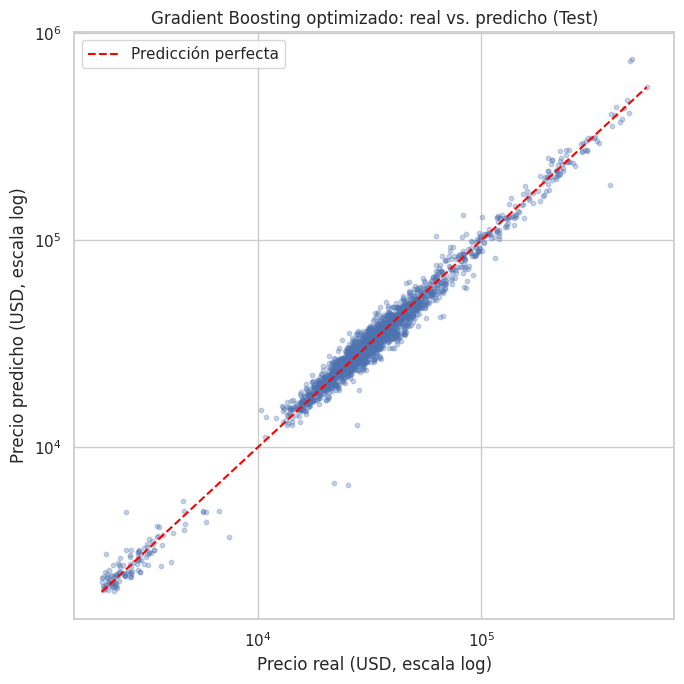

In [67]:
mejor = gb_opt
pred = np.exp(mejor.predict(X_test))
real = np.exp(y_test)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(real, pred, alpha=0.3, s=10)
lim = [real.min(), real.max()]
ax.plot(lim, lim, color="red", linestyle="--", label="Predicción perfecta")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Precio real (USD, escala log)")
ax.set_ylabel("Precio predicho (USD, escala log)")
ax.set_title("Gradient Boosting optimizado: real vs. predicho (Test)")
ax.legend()
plt.tight_layout()
plt.show()

**Análisis:** la mayoría de los puntos están pegados a la línea roja, lo que confirma la buena capacidad predictiva. La dispersión crece en los extremos: en los autos de preciosmuy elevados o muy bajos, donde hay pocos casos para aprender.


### 9. Importancia de variables vs. hipótesis inicial

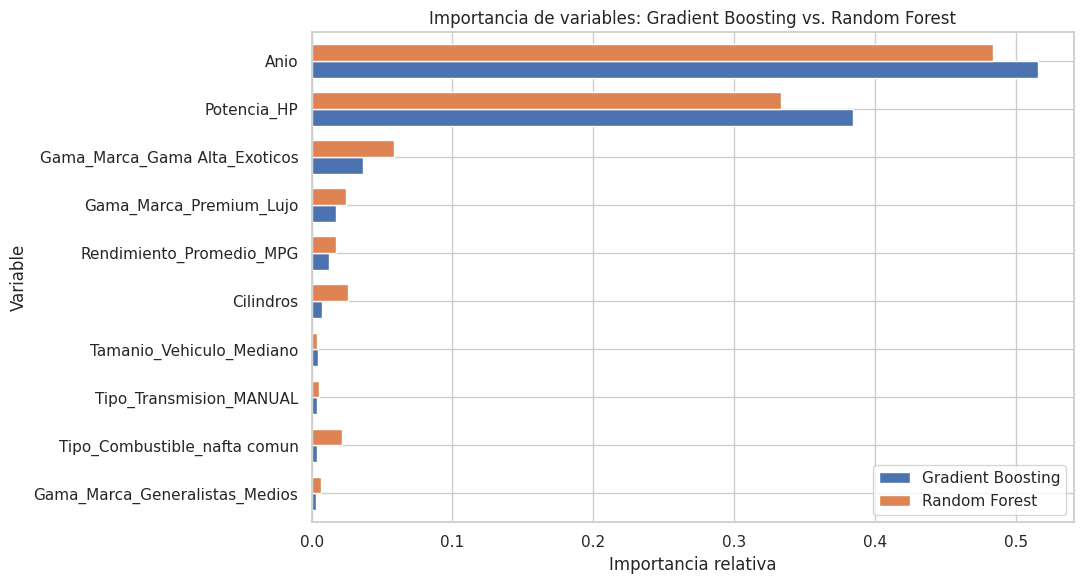

In [68]:
import pandas as pd
import matplotlib.pyplot as plt

imp = pd.DataFrame({
    "Gradient Boosting": gb_opt.feature_importances_,
    "Random Forest": rf_opt.feature_importances_
}, index=X_train.columns)

# Seleccionar las 10 variables más importantes
top10 = imp.mean(axis=1).nlargest(10).index

imp.loc[top10].sort_values(
    "Gradient Boosting"
).plot(
    kind="barh",
    figsize=(11, 6),
    width=0.7
)

plt.title("Importancia de variables: Gradient Boosting vs. Random Forest")
plt.xlabel("Importancia relativa")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

**Análisis:**

Los resultados muestran que ambos modelos coinciden en identificar a Anio y Potencia_HP como las variables más importantes para predecir el precio de un automóvil. Entre ambas concentran aproximadamente el 85-90% de la importancia total en cada modelo.

(**nos dicen cuánto contribuye cada variable a reducir el error durante la construcción de los árboles**)

En menor medida aparecen las gamas de marca, especialmente Gama Alta/Exóticos, seguidas por el rendimiento y la cantidad de cilindros.

Estos resultados respaldan nuestra hipótesis inicial de que el año, la potencia y la marca son factores relevantes para explicar el precio. Sin embargo, el año presenta una importancia mayor a la esperada y las gamas de marca una contribución relativamente menor.






### 10. Control de robustez: autos del mismo modelo en Train y en Test
Cada fila es una versión de un modelo (por ejemplo, varias versiones del Audi A4 2015). Con una división aleatoria, versiones casi idénticas del mismo modelo quedan una en Train y otra en Test, y el examen se vuelve más fácil de lo real. Para medir ese efecto, se repite la evaluación separando por `Modelo`: **ningún modelo de auto aparece a la vez en Train y en Test**.

In [69]:

from sklearn.model_selection import GroupShuffleSplit

# Separar por modelo de automóvil
grupos = data_gamas["Modelo"]

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

idx_tr, idx_te = next(gss.split(X_ml, y_ml, groups=grupos))

Xg_tr, Xg_te = X_ml.iloc[idx_tr], X_ml.iloc[idx_te]
yg_tr, yg_te = y_ml.iloc[idx_tr], y_ml.iloc[idx_te]

print(f"Train: {len(idx_tr)} filas ({grupos.iloc[idx_tr].nunique()} modelos de auto)")
print(f"Test: {len(idx_te)} filas ({grupos.iloc[idx_te].nunique()} modelos de auto)")
print(f"Proporción de filas en Test: {len(idx_te) / len(X_ml):.1%}")

# Modelos a comparar
modelos_grupos = [
    ("Regresión Lineal", LinearRegression()),
    ("Árbol sin límite", DecisionTreeRegressor(random_state=42)),
    ("Random Forest optimizado", RandomForestRegressor(
        random_state=42, **busqueda_rf.best_params_
    )),
    ("Gradient Boosting optimizado", GradientBoostingRegressor(
        random_state=42, **busqueda.best_params_
    ))
]

filas_g = []

for nombre, modelo in modelos_grupos:
    modelo.fit(Xg_tr, yg_tr)

    for conjunto, X, y in [
        ("Train", Xg_tr, yg_tr),
        ("Test", Xg_te, yg_te)
    ]:
        r = metricas(modelo, X, y)
        r["Modelo"] = nombre
        r["Conjunto"] = conjunto
        filas_g.append(r)

tabla_grupos = pd.DataFrame(filas_g).set_index(
    ["Modelo", "Conjunto"]
)

display(tabla_grupos.round(3))


Train: 8530 filas (656 modelos de auto)
Test: 1917 filas (164 modelos de auto)
Proporción de filas en Test: 18.3%


MAE (USD)           MSE  RMSE (USD)  R² (log)
Modelo                       Conjunto                                               
Regresión Lineal             Train     12231.825  1.342081e+09   36634.426     0.763
                             Test      11194.650  5.797877e+08   24078.781     0.710
Árbol sin límite             Train      2248.346  1.793138e+08   13390.811     0.993
                             Test      13693.981  6.351743e+09   79697.820     0.872
Random Forest optimizado     Train      2986.934  2.529350e+08   15903.931     0.991
                             Test       8424.166  9.997367e+08   31618.613     0.938
Gradient Boosting optimizado Train      2795.753  1.833826e+08   13541.885     0.991
                             Test       9046.186  2.118000e+09   46021.734     0.933

### Análisis del control de robustez

Al separar los datos para que ningún modelo de automóvil aparezca simultáneamente en Train y Test, **todos los algoritmos empeoran su rendimiento**. Esto sugiere que parte de los buenos resultados anteriores se debía a la presencia de versiones similares de vehículos en ambos conjuntos.

| Modelo | R² Test (aleatorio) | R² Test (por modelo) | MAE Test (por modelo) |
|---|---:|---:|---:|
| Regresión lineal | 0,743 | 0,710 | USD 11.195 |
| Árbol sin límite | 0,970 | 0,872 | USD 13.694 |
| Random Forest optimizado | 0,978 | **0,938** | **USD 8.424** |
| Gradient Boosting optimizado | 0,981 | 0,933 | USD 9.046 |

- **Árbol sin límite:** presenta la mayor caída de R², evidenciando una mayor dependencia de patrones específicos de los vehículos de entrenamiento y posibles problemas de sobreajuste.
- **Random Forest optimizado:** obtiene el mejor R² (0,938) y MAE (USD 8.424), superando ligeramente a Gradient Boosting en esta evaluación.
- **Errores extremos:** Random Forest y Gradient Boosting presentan RMSE elevados (USD 31.619 y USD 46.022), mientras que la regresión lineal obtiene USD 24.079. Esto podría deberse a dificultades para predecir vehículos de precios excepcionales, aunque sería necesario revisar los casos con mayores errores para confirmarlo.

**Conclusión:** los modelos de Machine Learning mantienen una ventaja en R² y MAE, pero su capacidad predictiva disminuye cuando deben estimar precios de modelos de automóviles completamente desconocidos.


#  Conclusión Final


1. **Modelo estadístico clásico (Regresión Lineal)**. Su principal fortaleza es la interpretabilidad. Permite analizar cómo se relaciona cada variable con el precio, manteniendo constantes las demás. Por ejemplo, cada año más reciente se asocia con un precio aproximadamente un 7% mayor, cada HP adicional con un 0,24% más y la transmisión manual con un precio alrededor de un 20% menor que la automática. El modelo explica aproximadamente el 75,6% de la variabilidad de Log_Precio, con resultados similares entre la muestra de 750 observaciones y la base completa.

2. **Modelos de Machine Learning**. Su principal fortaleza es la capacidad predictiva. Gradient Boosting optimizado obtuvo el mayor R² sobre Test (0,981) y el menor MAE (USD 3.871), reduciendo el error promedio aproximadamente un 67,5% respecto de la regresión lineal. Por otro lado, Random Forest optimizado consiguió el menor RMSE (USD 10.392). La validación cruzada respaldó el buen rendimiento de estos algoritmos.

3. elegiríamos inicialmente Random Forest optimizado, debido a su buen rendimiento general y mayor robustez en las pruebas realizadas. Aunque Gradient Boosting fue ligeramente superior en la división aleatoria, Random Forest obtuvo mejores resultados al predecir modelos de automóviles no vistos (R² = 0,938 y MAE = USD 8.424)